# Deconvolution

- **Question:** can a model trained on our own marrow single cells estimate
  the share of each cell type inside a bulk RNA-seq sample?
- **Method:** Scaden - a small ensemble of three neural networks (m256, m512,
  m1024) trained on artificial "pseudobulk" mixtures of single cells, each
  labelled with its true cell-type shares.
- **Two parts:**
  1. **Known truth** - mixtures built from two donors held out from training
     (MantonBM1, MantonBM8), so every prediction can be scored.
  2. **Real bulk** - GSE74246 (Corces et al. 2016): bulk RNA-seq of
     FACS-sorted healthy blood-forming populations, plus mixtures of them made
     at known shares.
- **Set-up:** raw counts, 19 fixed labels; train on MantonBM2-BM7 (28,846
  cells), test on MantonBM1 + MantonBM8 (9,584 cells); 500 cells per mixture;
  seed 7. Scaden 1.1.2 (TensorFlow, CPU) and a PyTorch rewrite of the same
  network (GPU) used for the later variants.
- **Scored at two levels:** the 19 labels, and 8 broad groups (sums of label
  shares): HSPC; Erythroid (early, late); Myeloid (Granulocyte precursor, both
  monocytes); Dendritic (Dendritic cell, Plasmacytoid DC); Platelet; B lineage
  (Pre-B large, Pre-B small, B naive); T cells (the six T labels); NK.
- **Main measure: CCC** (Lin's concordance correlation). Pearson r rewards
  predictions that rise and fall with the truth at any scale; CCC also
  penalises predictions off the identity line. A label predicted at half its
  true share everywhere has r = 1 and a low CCC.
- **Code:** `src/deconvolution/`. Order: `scaden_check`, `pseudobulk_train`,
  `pseudobulk_test`, `scaden_fit`, `pseudobulk_score`, `donor_diagnostics`,
  `scaden_weights`, `scaden_torch_fit`, `scaden_torch_loss`,
  `scaden_torch_variants`, `variant_score`, `corces_bulk`,
  `scaden_torch_bulk` (`counts`, `length`), `bulk_score`. Envs: `sc_deconv`
  (Scaden), `sc_core` (everything else).
- **This notebook** only reads saved tables and figures. 15 of the 27 stage
  figures are shown; the rest are linked at the end.

In [1]:
from io import BytesIO
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "figures"
RESULTS = ROOT / "results"
MAX_PIXELS = 1600

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.precision", 3)


def show(figure: str, width: int = 900) -> None:
    """Saved figure, downscaled for display, with a link to the full file."""
    with PILImage.open(FIGURES / figure) as image:
        image.thumbnail((MAX_PIXELS, MAX_PIXELS * 4))
        buffer = BytesIO()
        image.convert("RGB").save(buffer, format="JPEG", quality=85)
    display(Image(data=buffer.getvalue(), format="jpeg", width=width),
            Markdown(f"[Full-resolution figure](../figures/{figure})"))


def table(name: str, **read_options) -> pd.DataFrame:
    """Saved results table, read from the results directory."""
    return pd.read_csv(RESULTS / name, **read_options)

## 1. Donor split and the Scaden check

In [2]:
LABELS = ["HSPC", "Granulocyte precursor", "Monocyte classical", "Monocyte non-classical",
          "Dendritic cell", "Plasmacytoid DC", "Erythroid early", "Erythroid late", "Platelet",
          "Pre-B large", "Pre-B small", "B naive", "CD4 T naive", "CD4 T memory", "T activated",
          "CD8 T memory", "CD8 T cytotoxic", "NK", "T proliferating"]
train_cells = table("deconvolution/pseudobulk_train/pseudobulk_train_cell_types.csv", index_col=0)
test_cells = table("deconvolution/pseudobulk_test/pseudobulk_test_cell_types.csv", index_col=0)
cells = pd.DataFrame({"training (BM2–BM7)": train_cells["source_cells"],
                      "test MantonBM1": test_cells["cells_MantonBM1"],
                      "test MantonBM8": test_cells["cells_MantonBM8"]})
display(cells.sort_values("training (BM2–BM7)", ascending=False).T)
check = table("deconvolution/scaden_check/scaden_check_summary.csv")
check.assign(value=check["value"].map("{:.4g}".format))

,CD4 T naive,Monocyte classical,B naive,CD8 T cytotoxic,NK,CD8 T memory,CD4 T memory,Erythroid early,Monocyte non-classical,HSPC,Pre-B small,Granulocyte precursor,T activated,Erythroid late,Dendritic cell,Plasmacytoid DC,Pre-B large,Platelet,T proliferating
training (BM2–BM7),7667,3955,3896,2023,1944,1837,1782,914,833,693,678,663,553,433,381,265,219,77,33
test MantonBM1,1600,366,648,83,121,444,368,121,32,105,267,126,0,106,33,26,85,18,4
test MantonBM8,1498,709,474,201,88,696,563,116,36,175,80,137,30,58,83,39,30,8,10


,check,value,passed
0,signature genes,1.777e+04,True
1,sub-models reloaded,3,True
2,largest deviation of a row sum from 1,1.04e-07,True
3,"RMSE, mean-fraction baseline",0.03253,True
4,"RMSE, Scaden",0.02792,True
5,"Pearson r, all fractions",0.5411,True


- **Why MantonBM1 + MantonBM8 are held out:** of all donor pairs (MantonBM3
  excluded) they sit closest to the average composition and are the only pair
  keeping at least 14 cells of every label on the test side. MantonBM3 stays
  in training because it holds 532 of the 583 T activated cells.
- **Weak spots carried into every test result:** only 14 T proliferating and
  26 Platelet cells on the test side (33 and 77 in training). Their mixtures
  reuse the same few cells many times.
- **MantonBM1 has no T activated cells at all**; its donor mixtures carry none.
- **The Scaden check** (400 small training mixtures, 300 steps, 20 test
  mixtures) proves the set-up works: 3 sub-models reload, predictions sum to 1,
  and Scaden beats the "predict the average" baseline (RMSE 0.028 against
  0.033, r 0.54).
- **What the check found:** training on 100-cell and testing on 500-cell
  mixtures made Scaden *worse* than the baseline, and ten times more training
  data did not help. Matching the mixture size fixed it. Scaden scales each
  sample on its own (log, then min-max), so mixtures of different sizes look
  different to it. **All mixtures here are 500 cells.**
- **Four silent faults were fixed before any real run:** Scaden 1.1.2 breaks
  under Keras 3 and then predicts with an *untrained* network without warning
  (fixed with legacy Keras); it silently reuses an old model in its folder
  (folder now deleted before training); its gene order is random (genes now
  chosen and sorted by our code); and the env pointed at a missing pin file.

## 2. Training and test mixtures

In [3]:
train = table("deconvolution/pseudobulk_train/pseudobulk_train_fractions.csv", index_col=0)
test = table("deconvolution/pseudobulk_test/pseudobulk_test_fractions.csv", index_col=0)


def mixture_summary(fractions: pd.DataFrame) -> pd.Series:
    """Counts and share ranges describing one set of mixtures."""
    present = (fractions[LABELS] > 0).sum(axis=1)
    return pd.Series({
        "mixtures": len(fractions),
        "labels per mixture, min": int(present.min()),
        "labels per mixture, median": int(present.median()),
        "labels per mixture, max": int(present.max()),
        "largest share of any label": fractions[LABELS].max(axis=None),
        "CD4 T naive share ≥ 0.17": int((fractions["CD4 T naive"] >= 0.17).sum()),
        "CD4 T naive share ≥ 0.28": int((fractions["CD4 T naive"] >= 0.28).sum()),
    }, dtype=object)


sets = {f"train {kind}": frame for kind, frame in train.groupby("kind")}
sets.update({f"test {kind}": frame for kind, frame in test.groupby("set")})
pd.DataFrame({name: mixture_summary(frame) for name, frame in sets.items()})

,train partial,train random,test donor,test partial,test random
mixtures,4000,4000,500,500,500
"labels per mixture, min",1,16,12,1,17
"labels per mixture, median",9,19,16,9,19
"labels per mixture, max",18,19,19,18,19
largest share of any label,1.0,0.194,0.48,1.0,0.17
CD4 T naive share ≥ 0.17,293,0,499,35,0
CD4 T naive share ≥ 0.28,98,0,383,13,0


In [4]:
test_cells[["mean_fraction_random", "mean_fraction_donor", "present_donor"]].sort_values(
    "mean_fraction_donor", ascending=False).round(3)

,mean_fraction_random,mean_fraction_donor,present_donor
CD4 T naive,0.052,0.325,1.000
CD8 T memory,0.054,0.118,1.000
B naive,0.053,0.116,1.000
Monocyte classical,0.052,0.113,1.000
CD4 T memory,0.051,0.096,1.000
Pre-B small,0.053,0.038,0.980
CD8 T cytotoxic,0.050,0.029,0.986
HSPC,0.051,0.029,0.986
Granulocyte precursor,0.051,0.027,0.990
Erythroid early,0.053,0.024,0.988


- **Training: 8,000 mixtures** (4,000 *random*: random shares over all 19
  labels; 4,000 *partial*: a random subset of 1-18 labels), built with our own
  mixer - Scaden's simulator has no seed and labels mixtures with the shares
  it *aimed* for, not the cells it drew.
- **Every label averages about 1 in 19 (0.052)** in random mixtures, whatever
  its real abundance, and **no label ever exceeds 0.19** in a random mixture.
  Only partial mixtures reach high shares: just 98 of 8,000 have CD4 T naive at
  0.28 or more.
- **Test: 1,500 mixtures** - 500 random, 500 partial and 500 **donor**
  mixtures (250 per donor, built only from that donor's cells around its real
  composition). **The donor set is the realistic one**: CD4 T naive averages
  0.32 (range 0.17-0.48), five labels hold 77% of each mixture, and eight
  labels average under 2% and are often absent (T proliferating present in
  only 24% of donor mixtures).
- **So the donor set lies partly outside the training range** (large CD4 T
  naive shares; very small rare-label shares). It is the closest to real bulk.

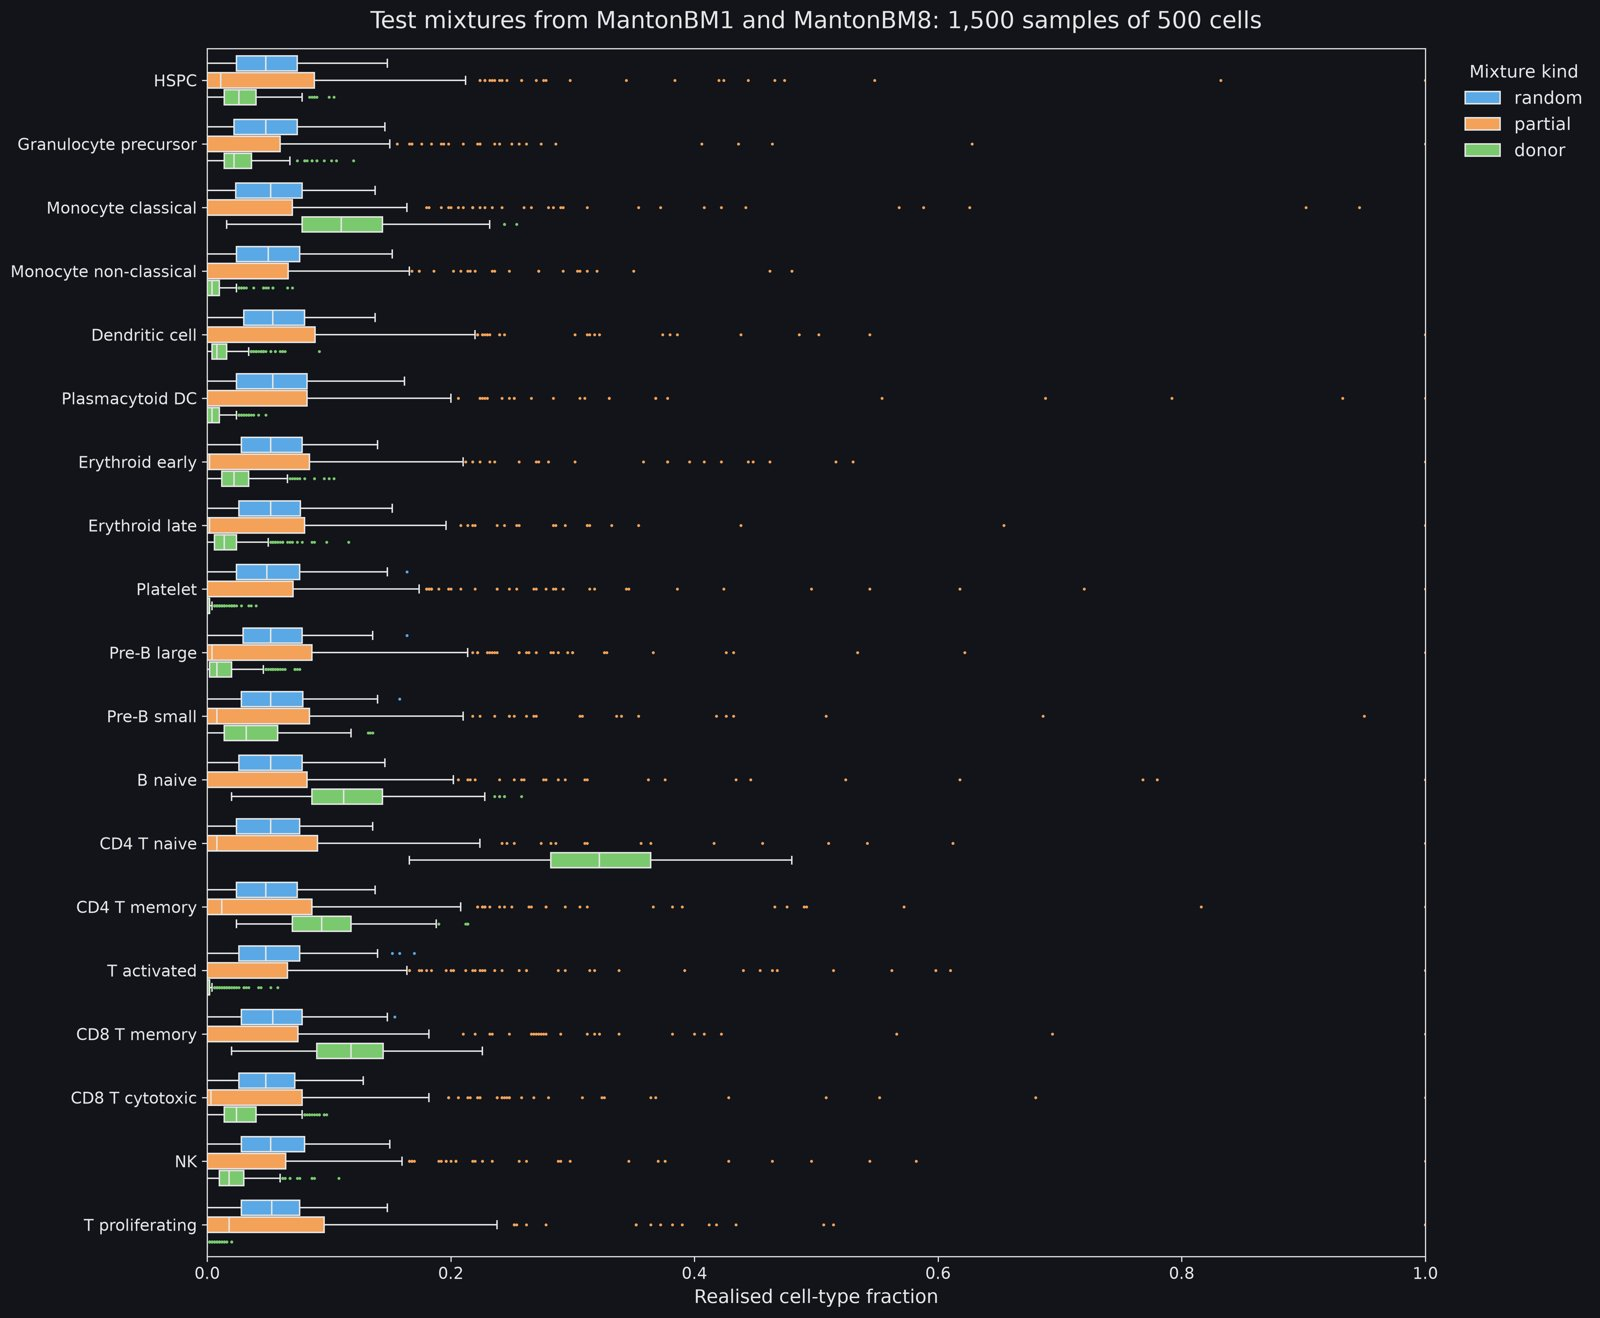

[Full-resolution figure](../figures/deconvolution/pseudobulk_test/pseudobulk_test_fractions.png)

In [5]:
show("deconvolution/pseudobulk_test/pseudobulk_test_fractions.png", width=800)

- **Share of each label in the test mixtures**, fixed 0-1 axis; blue random,
  orange partial, green donor.
- **Blue and orange treat every label the same** (random boxes about
  0.025-0.075; partial boxes start at zero with points across the axis).
- **Green stands apart**: CD4 T naive far right (box about 0.28-0.37), B naive,
  Monocyte classical and CD8 T memory at about 0.09-0.15, the rare labels as
  thin boxes against zero.
- The training figure (linked) repeats the blue and orange pattern.

## 3. Scaden training and scoring on held-out donors

In [6]:
display(table("deconvolution/scaden_fit/scaden_fit_summary.csv", index_col=0).T)
truth = test[LABELS]
sub_models = table("deconvolution/scaden_fit/scaden_fit_sub_models.csv")
ensemble = table("deconvolution/scaden_fit/scaden_fit_predictions.csv", index_col=0)


def rmse(predicted: pd.DataFrame) -> float:
    """Root-mean-square error against the true shares over all mixtures and labels."""
    return float(((predicted[LABELS] - truth.loc[predicted.index]) ** 2).to_numpy().mean() ** 0.5)


pd.Series({**{model: rmse(frame.set_index("sample")) for model, frame in sub_models.groupby("model")},
           "ensemble (mean)": rmse(ensemble)}, name="RMSE, 1,500 test mixtures").map("{:.4f}".format).to_frame().T

,training mixtures,test mixtures,genes,training steps per sub-model,training minutes,largest deviation of a row sum from 1
value,8000.0,1500.0,18366.0,5000.0,48.3,1.788e-07


,m1024,m256,m512,ensemble (mean)
"RMSE, 1,500 test mixtures",0.0476,0.0438,0.0485,0.0445


- **18,366 genes** (Scaden's rule: variance > 0.1 across the test mixtures);
  5,000 steps per sub-model; 48 min on the CPU. All three sub-models reload;
  every prediction sums to 1.
- **The ensemble is not better than its best member** (m256 alone 0.0438
  against 0.0445): the three sub-models make largely the same mistakes.
- **The gene list depends on the bulk being predicted**, so real bulk needs
  its own training run (section 7).

In [7]:
scores = table("deconvolution/pseudobulk_score/pseudobulk_score.csv")
per_label = scores[scores["cell_type"] != "all"]
headline = per_label.groupby(["model", "level", "subset"]).agg(
    ccc_median=("ccc", "median"), ccc_min=("ccc", "min"), ccc_max=("ccc", "max"),
    pearson_median=("pearson", "median"))
headline.loc["scaden"].round(2)

ccc_median  ccc_min  ccc_max  pearson_median
level subset                                                       
group donor                  0.36     0.03     0.89            0.77
      donor MantonBM1        0.50     0.08     0.79            0.81
      donor MantonBM8        0.26     0.03     0.83            0.88
      partial                0.85     0.55     0.96            0.95
      random                 0.72     0.39     0.81            0.91
label donor                  0.40    -0.08     0.70            0.77
      donor MantonBM1        0.37     0.00     0.75            0.75
      donor MantonBM8        0.22     0.00     0.71            0.73
      partial                0.79     0.05     0.97            0.93
      random                 0.60     0.07     0.89            0.82

- **Median per-label CCC on the realistic donor set: 0.40** (groups 0.36),
  against 0.60 random and 0.79 partial.
- **Median Pearson r on the donor set: 0.77.** Scaden puts samples in the right
  order far more often than it gets the level right.
- **Partial scores highest despite the largest error** - its true shares span
  0 to 1, and a wide range makes any correlation easier. Read correlation and
  error together.
- **MantonBM8 is clearly worse than MantonBM1** (labels 0.22 vs 0.37; groups
  0.26 vs 0.50).
- The pooled "all labels" CCC (0.84 donor) is not used: pooling rewards a
  model that only knows which labels are large.

In [8]:
donor = per_label[(per_label["model"] == "scaden") & (per_label["level"] == "label")]
by_donor = donor.pivot(index="cell_type", columns="subset", values="bias")
donor[donor["subset"] == "donor"].set_index("cell_type")[
    ["true_mean", "predicted_mean", "bias", "pearson", "ccc", "relative_mae"]].join(
    by_donor[["donor MantonBM1", "donor MantonBM8"]].add_prefix("bias, ")).sort_values(
    "true_mean", ascending=False).round(3)

,true_mean,predicted_mean,bias,pearson,ccc,relative_mae,"bias, donor MantonBM1","bias, donor MantonBM8"
cell_type,,,,,,,,
CD4 T naive,0.325,0.245,-0.080,0.854,0.499,0.252,-0.043,-0.117
CD8 T memory,0.118,0.052,-0.065,0.791,0.158,0.555,-0.053,-0.077
B naive,0.116,0.082,-0.034,0.912,0.626,0.293,-0.035,-0.032
Monocyte classical,0.113,0.074,-0.038,0.950,0.617,0.340,-0.030,-0.046
CD4 T memory,0.096,0.075,-0.021,0.439,0.250,0.298,-0.002,-0.039
Pre-B small,0.038,0.034,-0.004,0.860,0.572,0.433,-0.018,0.010
CD8 T cytotoxic,0.029,0.055,0.025,0.720,0.396,0.899,0.021,0.030
HSPC,0.029,0.037,0.008,0.896,0.626,0.415,0.012,0.004
Granulocyte precursor,0.027,0.030,0.003,0.627,0.502,0.437,-0.002,0.008


- **Predictions are pulled toward the training average (1 in 19).** All five
  labels above 0.09 are under-predicted (CD4 T naive −0.080, CD8 T memory
  −0.065); every label under 0.03 except Pre-B small is over-predicted. The
  sign flips near 0.04-0.05 - the 1-in-19 training average. Cause: random
  training mixtures never put a label above 0.19 and give every label the same
  average.
- **A floor for absent labels**: rare labels are never predicted near zero
  (about 0.02). Below about 1% the predicted share carries no information
  (relative error 2.9× to 18.5× the true share).
- **Labels that work** (CCC ≥ 0.6): Erythroid early 0.70, B naive 0.63, HSPC
  0.63, Monocyte classical 0.62 - the labels with distinctive programmes in
  earlier stages.
- **Fine T labels are not separated** (CD8 T memory 0.16, CD4 T memory 0.25);
  share is moved between the two CD8 labels. **T activated, T proliferating
  and Platelet are not learned at all** (CCC ≤ 0.03); Platelet and
  T proliferating are under-predicted even on the random set, where they
  average 0.05.
- **MantonBM8 carries a donor-specific error**: CD4 T naive −0.117 (MantonBM1
  −0.043), Erythroid late +0.074 (+0.007), T activated +0.069 (+0.041).
  T-cell share is moved into Erythroid late and T activated - tested in
  section 4.

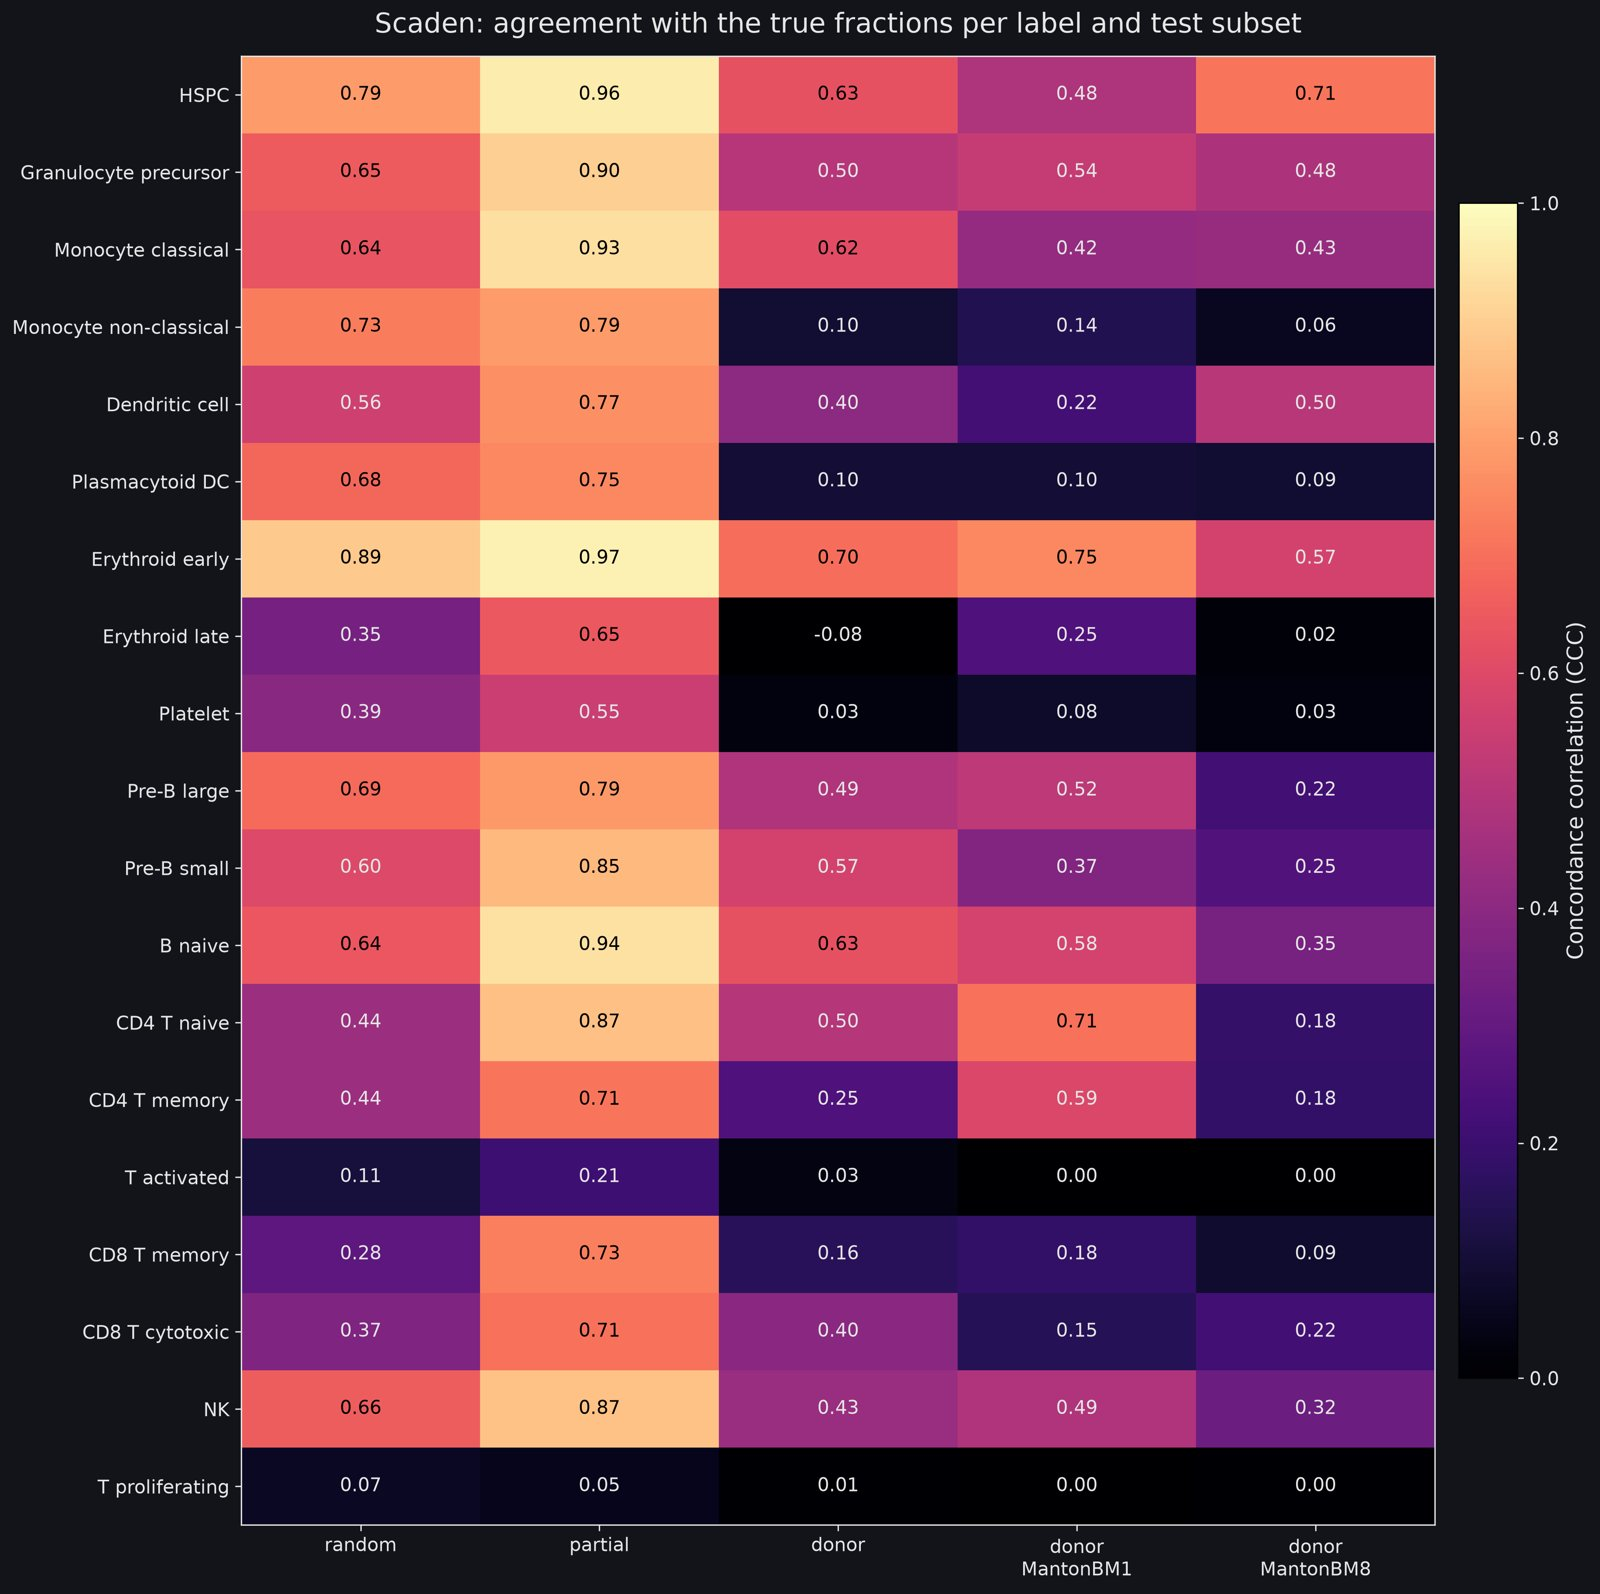

[Full-resolution figure](../figures/deconvolution/pseudobulk_score/pseudobulk_score_scaden_label_ccc.png)

In [9]:
show("deconvolution/pseudobulk_score/pseudobulk_score_scaden_label_ccc.png", width=700)

- **CCC per label and test subset**, Scaden.
- **Bright partial column, mid random, dark donor columns.** The darkest rows
  are T activated, T proliferating, Platelet and Erythroid late; the brightest
  Erythroid early and HSPC.
- **MantonBM1 is much brighter than MantonBM8 for CD4 T naive (0.71 vs 0.18)
  and CD4 T memory (0.59 vs 0.18).**

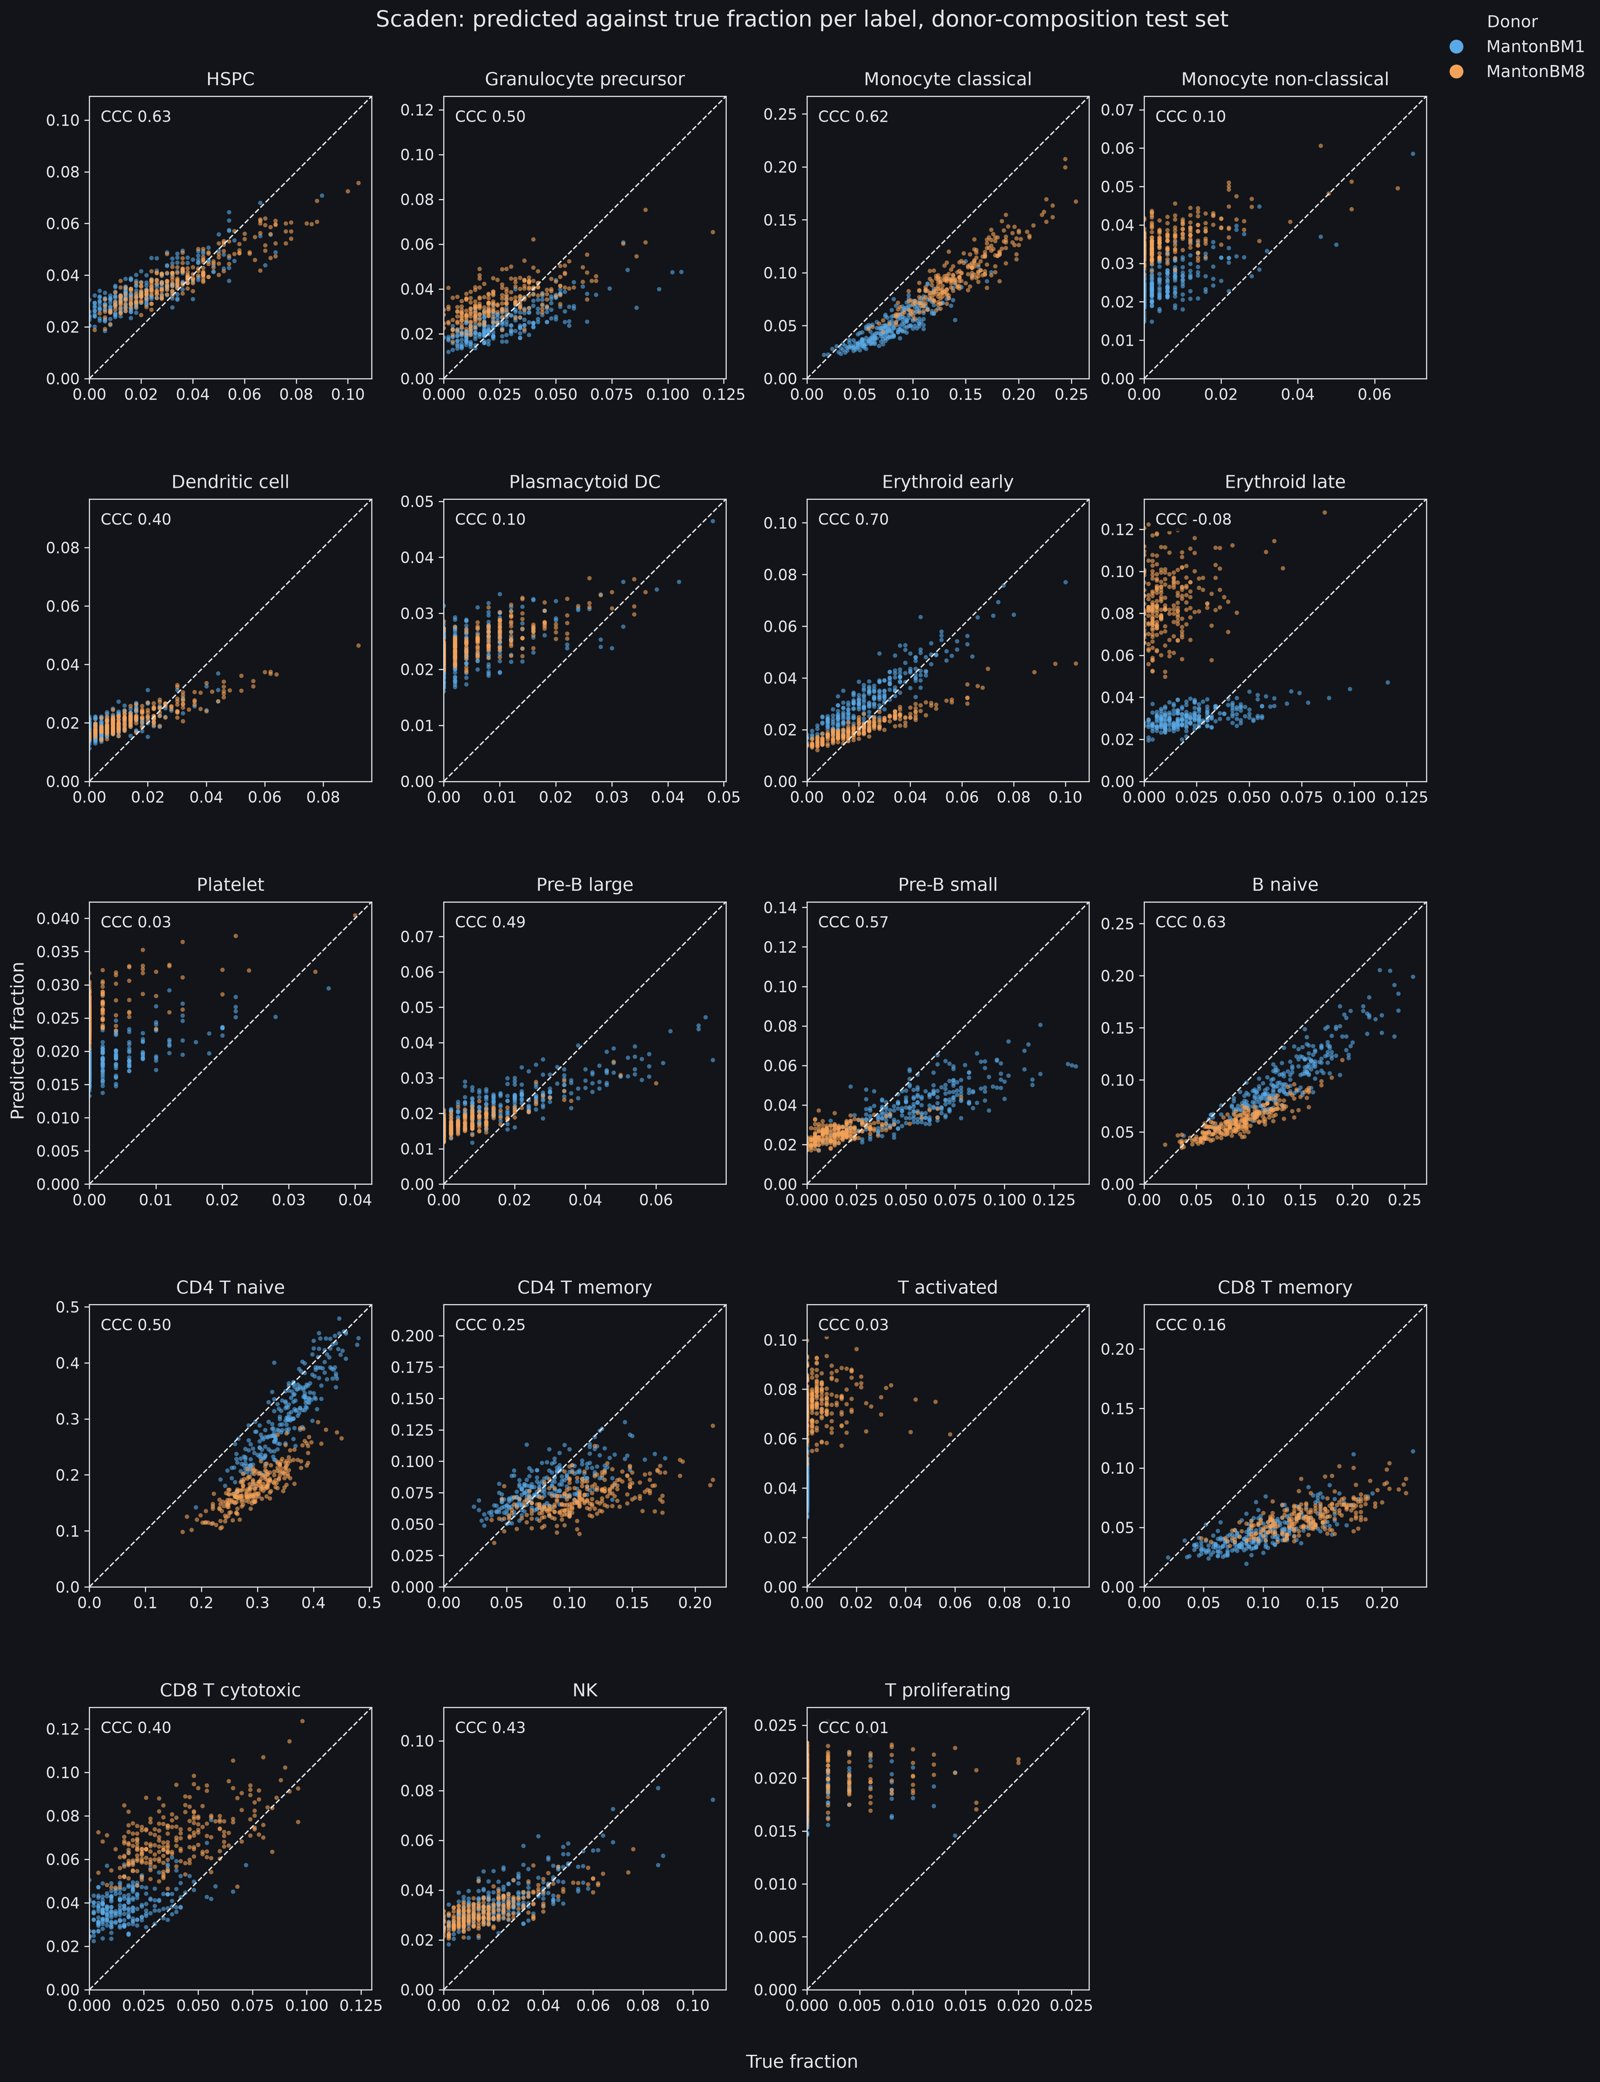

[Full-resolution figure](../figures/deconvolution/pseudobulk_score/pseudobulk_score_scaden_label_scatter.png)

In [10]:
show("deconvolution/pseudobulk_score/pseudobulk_score_scaden_label_scatter.png", width=800)

- **Predicted against true share per label, donor set**; blue MantonBM1,
  orange MantonBM8; dashed line = perfect.
- **Three shapes recur:**
  - **straight clouds below the line** for the large labels (Monocyte
    classical, B naive, CD8 T memory) - right order, too low: shrinkage;
  - **vertical stacks at true 0** for the rare labels (T proliferating at
    predicted 0.015-0.023, Platelet 0.013-0.032) - the floor;
  - **two separate donor clouds** for Erythroid late (MantonBM8 at
    0.06-0.12, MantonBM1 at 0.02-0.04), T activated and CD4 T naive - the
    MantonBM8 error. Erythroid late's negative CCC comes from the two clouds,
    not from a reversed signal within either donor.

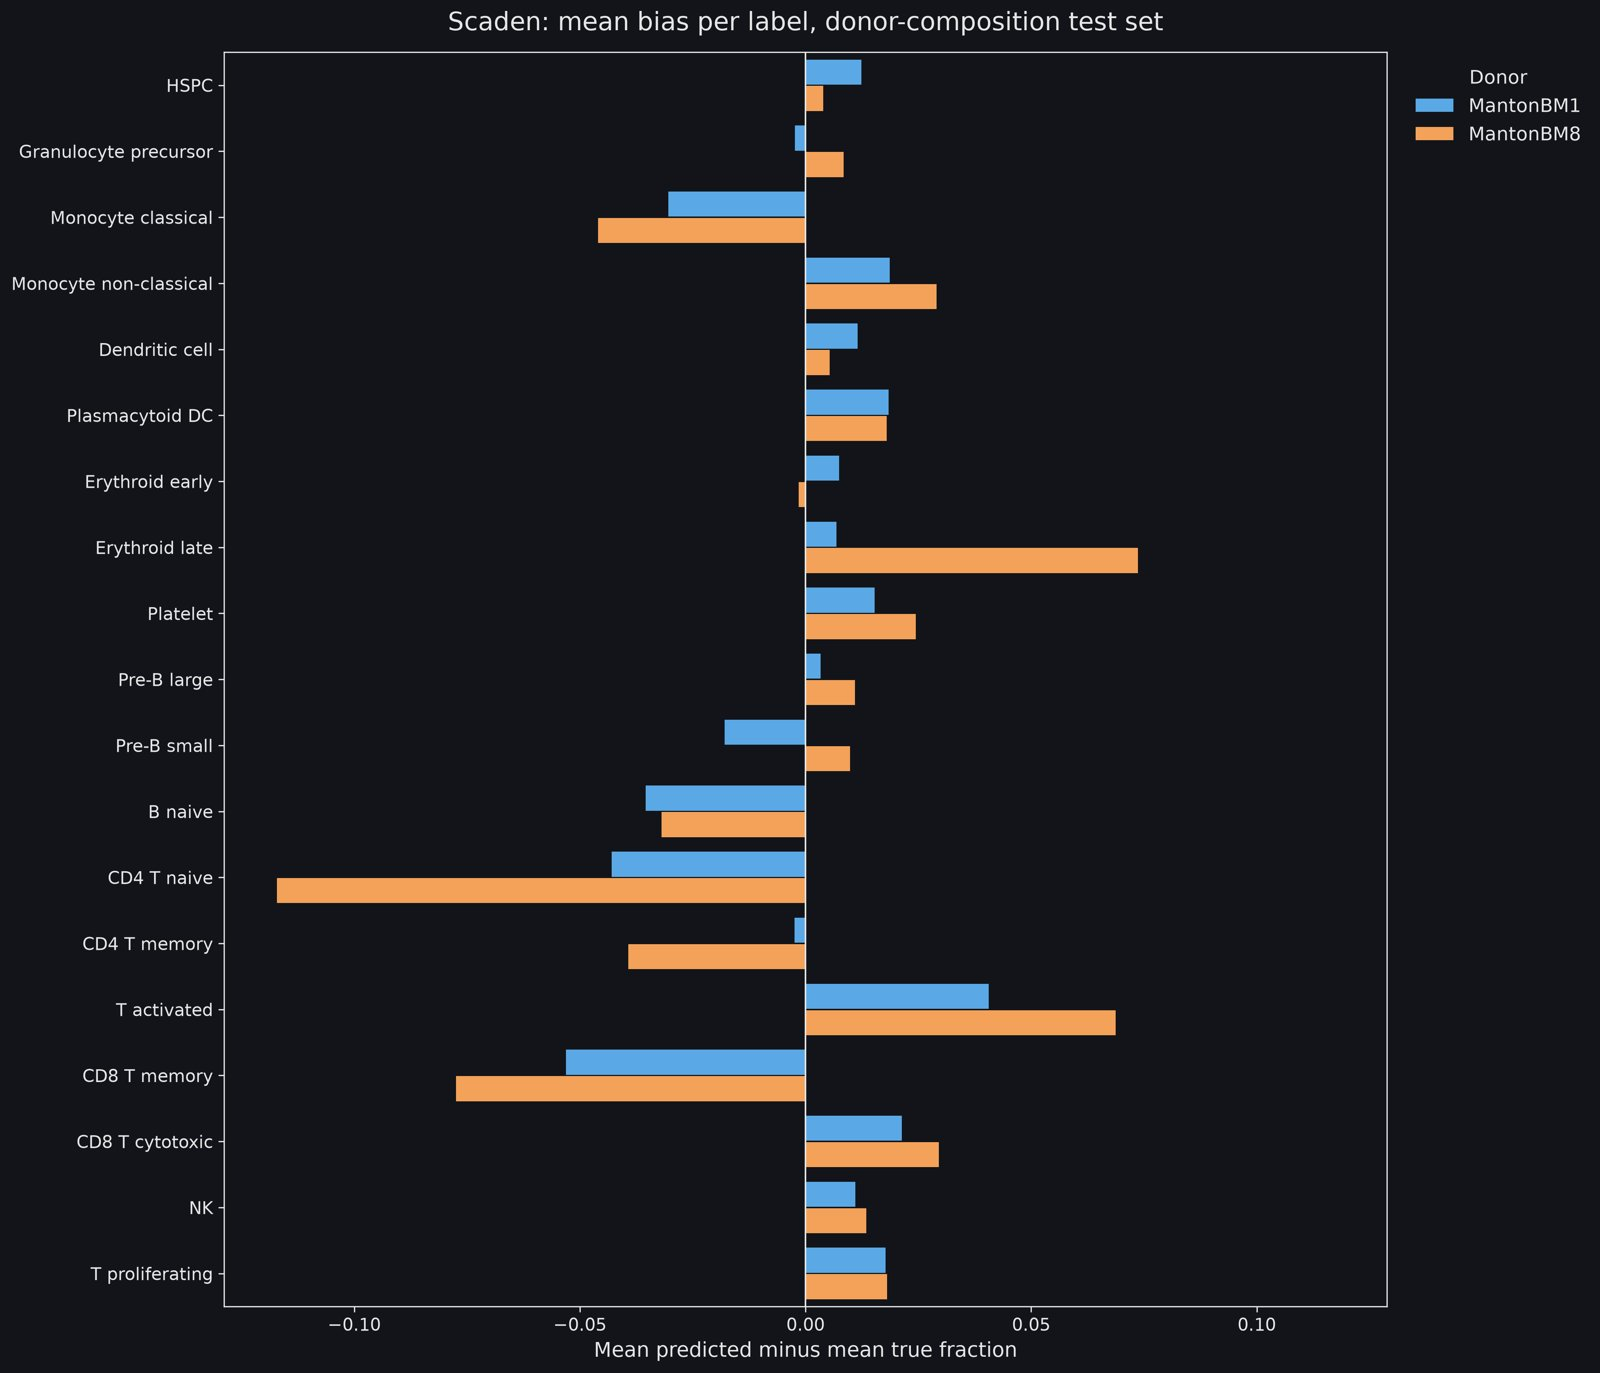

[Full-resolution figure](../figures/deconvolution/pseudobulk_score/pseudobulk_score_scaden_label_bias.png)

In [11]:
show("deconvolution/pseudobulk_score/pseudobulk_score_scaden_label_bias.png", width=750)

- **Mean predicted minus mean true share per label and donor.**
- **Long negative bars** for CD4 T naive and CD8 T memory, **long positive
  bars** for T activated and Erythroid late - and in each of these four the
  MantonBM8 bar is the longer one.

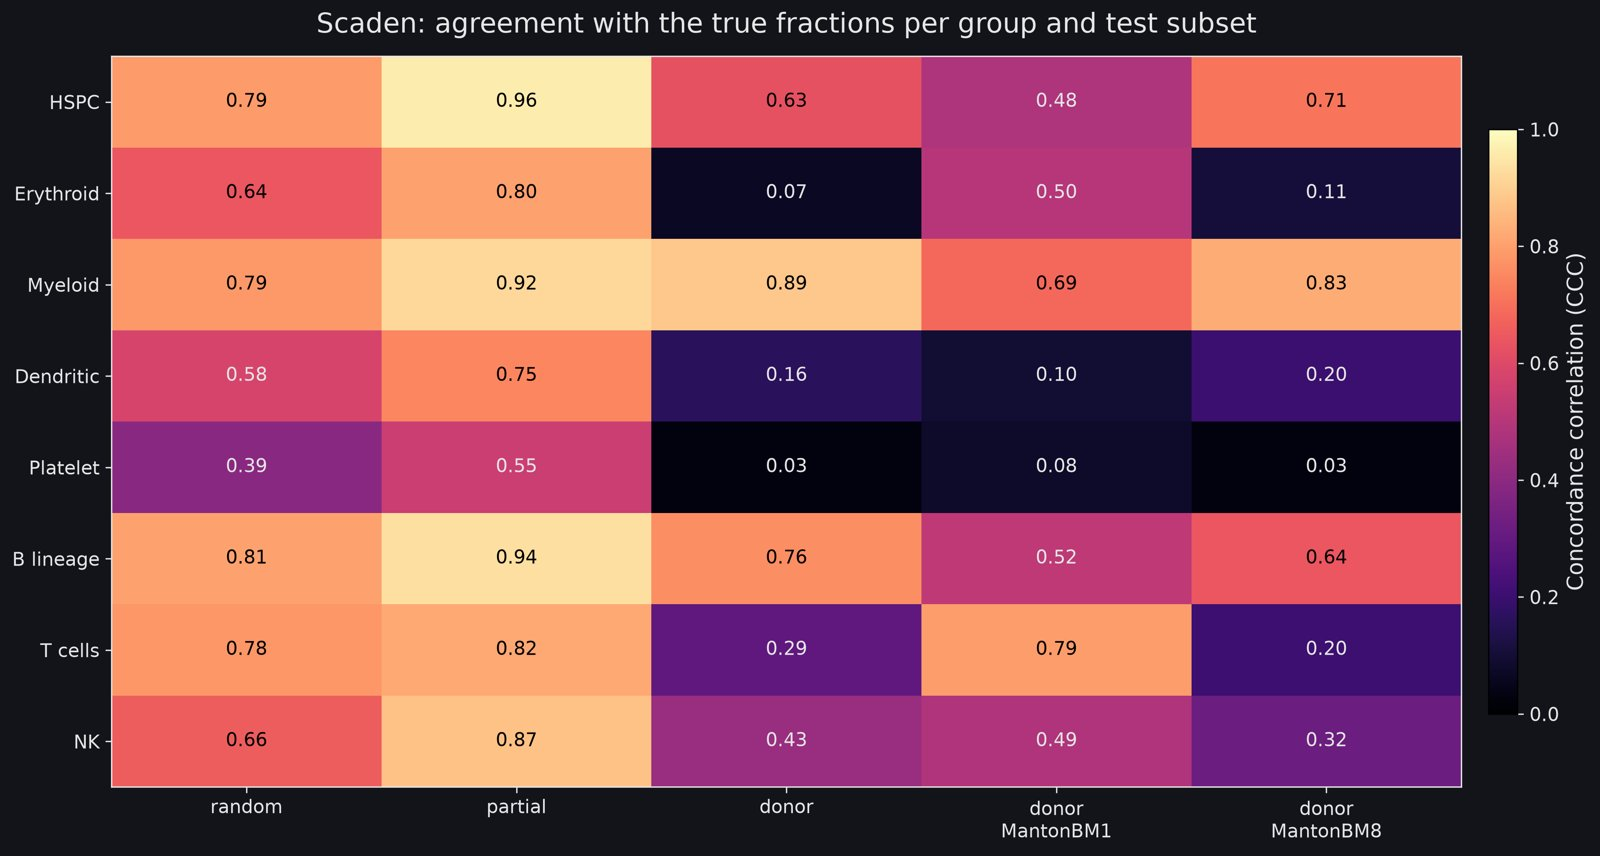

[Full-resolution figure](../figures/deconvolution/pseudobulk_score/pseudobulk_score_scaden_group_ccc.png)

In [12]:
show("deconvolution/pseudobulk_score/pseudobulk_score_scaden_group_ccc.png", width=750)

- **CCC per broad group.**
- **Myeloid (0.89 donor) and B lineage (0.76 donor) are the reliable groups.**
- **T cells: 0.79 in MantonBM1, 0.20 in MantonBM8** - summing the T labels does
  not rescue MantonBM8. Erythroid (0.07), Dendritic (0.16) and Platelet (0.03)
  collapse in the donor columns.

## 4. Why MantonBM8 fails: two tests

In [13]:
haemoglobin = table("deconvolution/donor_diagnostics/donor_diagnostics_haemoglobin.csv").dropna()
haemoglobin["percent"] = 100 * haemoglobin["mean_haemoglobin"]
haemoglobin.groupby("donor").agg(
    median_percent=("percent", "median"), min_percent=("percent", "min"), max_percent=("percent", "max"),
    median_share_of_cells=("share_haemoglobin", "median")).round(3)

,median_percent,min_percent,max_percent,median_share_of_cells
donor,,,,
MantonBM1,0.033,0.014,0.041,0.409
MantonBM2,0.025,0.008,0.074,0.403
MantonBM3,0.013,0.007,0.024,0.232
MantonBM4,0.048,0.021,0.069,0.570
MantonBM5,0.045,0.026,0.187,0.586
MantonBM6,0.018,0.005,0.036,0.338
MantonBM7,0.021,0.013,0.066,0.327
MantonBM8,0.033,0.016,0.054,0.463


- **Test 1 - free (ambient) haemoglobin RNA in MantonBM8: rejected.**
  Haemoglobin as % of counts in non-erythroid cells (10 HB genes; groups of
  ≥ 20 cells): MantonBM8 sits mid-pack (median 0.033%) - *equal* to MantonBM1,
  which shows no Erythroid late error.
- **The most haemoglobin is in two training donors** (MantonBM4 0.048%,
  MantonBM5 0.045%; highest single group MantonBM5 Dendritic cell 0.19%);
  MantonBM3 is the cleanest. The level is under 0.2% everywhere - far below
  what a few real erythroid cells add to a mixture.

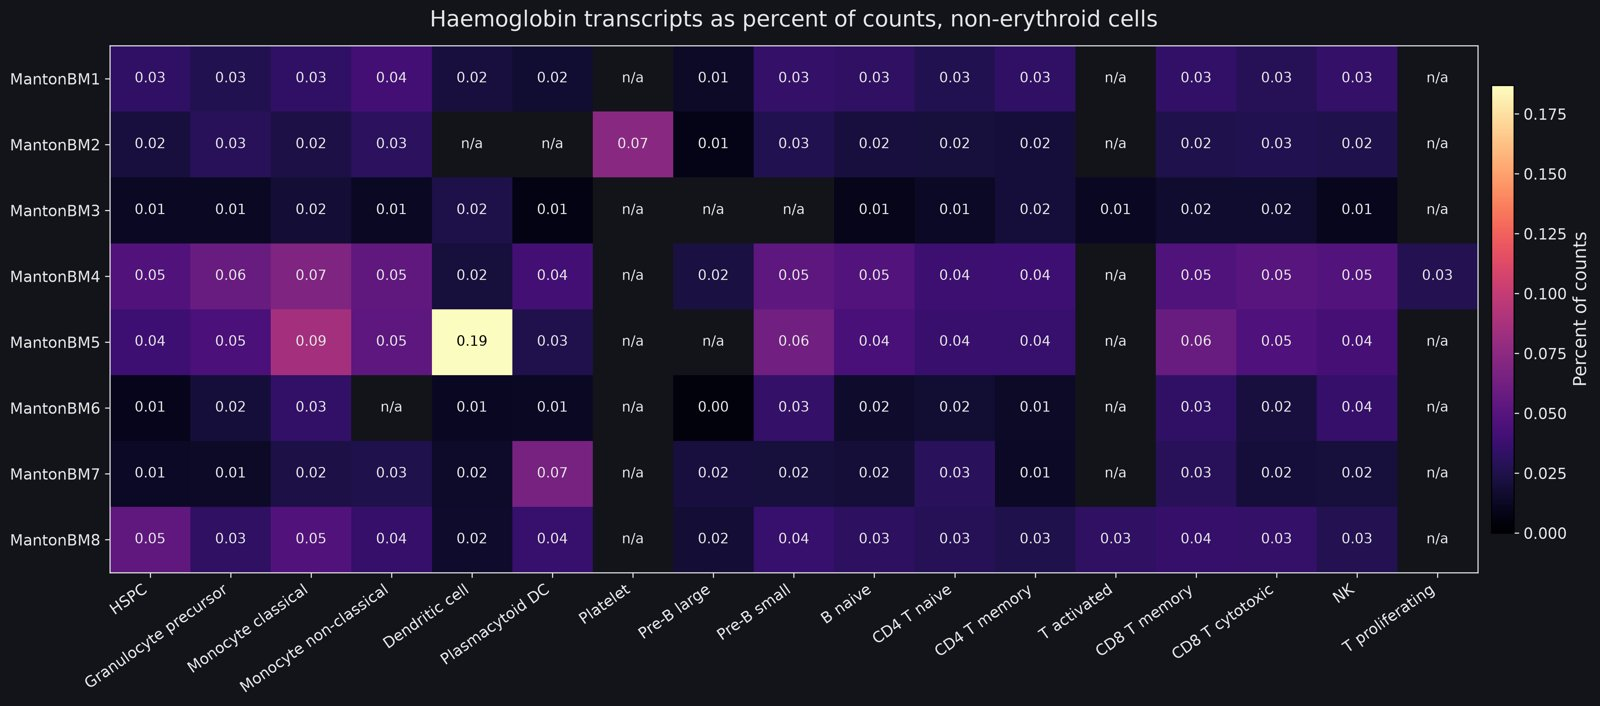

[Full-resolution figure](../figures/deconvolution/donor_diagnostics/donor_diagnostics_haemoglobin.png)

In [14]:
show("deconvolution/donor_diagnostics/donor_diagnostics_haemoglobin.png")

- **Haemoglobin % per donor and cell type**; n/a = fewer than 20 cells.
- **No MantonBM8 row stands out.** The one bright cell is MantonBM5 Dendritic
  cell; MantonBM4 and MantonBM5 are the warmest rows; MantonBM3 the darkest.

In [15]:
from operator import itemgetter

activation = table("deconvolution/donor_diagnostics/donor_diagnostics_activation.csv").dropna()
genes = ["CD69", "FOS", "JUN", "JUNB", "DUSP1"]
means = activation.set_index(["cell_type", "donor"])[[f"mean_{gene}" for gene in genes]]
means.columns = genes
top_donor = means.groupby(level="cell_type").idxmax().map(itemgetter(1))
display(top_donor.rename_axis("donor with the highest mean"))
means.xs("MantonBM8", level="donor").round(2).join(
    means.drop("MantonBM8", level="donor").groupby(level="cell_type").max().round(2), rsuffix=", max of other donors")

,CD69,FOS,JUN,JUNB,DUSP1
donor with the highest mean,,,,,
CD4 T memory,MantonBM3,MantonBM8,MantonBM8,MantonBM8,MantonBM8
CD4 T naive,MantonBM3,MantonBM8,MantonBM8,MantonBM8,MantonBM8
CD8 T cytotoxic,MantonBM8,MantonBM8,MantonBM8,MantonBM6,MantonBM8
CD8 T memory,MantonBM4,MantonBM8,MantonBM8,MantonBM4,MantonBM8
T activated,MantonBM3,MantonBM8,MantonBM8,MantonBM8,MantonBM8


,CD69,FOS,JUN,JUNB,DUSP1,"CD69, max of other donors","FOS, max of other donors","JUN, max of other donors","JUNB, max of other donors","DUSP1, max of other donors"
cell_type,,,,,,,,,,
CD4 T naive,1.03,1.35,2.11,2.81,1.90,1.14,1.31,1.95,2.43,1.07
CD4 T memory,1.64,2.72,2.56,3.16,2.66,1.94,2.35,2.43,2.91,1.86
T activated,1.35,1.86,2.46,2.72,2.50,1.47,0.99,1.58,2.34,1.20
CD8 T memory,1.69,1.96,2.95,2.67,2.82,1.81,1.54,2.56,2.68,2.38
CD8 T cytotoxic,0.94,1.16,2.15,1.88,2.07,0.73,0.73,1.91,2.02,1.19


- **Test 2 - a stress signature read as "T activated": supported.**
  FOS, JUN, JUNB and DUSP1 are immediate-early genes, switched on within
  minutes of stress such as sample handling.
- **MantonBM8 has the highest mean in all four T labels present in every donor
  for FOS, JUN and DUSP1** (2 of 4 for JUNB, 1 of 4 for CD69); with T activated
  (shared only with MantonBM3) it is 5 of 5. 78% of MantonBM8 CD4 T naive cells
  express DUSP1, against 23-51% in the other donors.
- **The model learned "T activated" from MantonBM3** (532 of its 553 training
  cells): CD69 1.47, FOS 0.99, JUN 1.58, JUNB 2.34, DUSP1 1.20. MantonBM8's
  ordinary CD4 T naive cells match or exceed this on FOS, JUN, JUNB and DUSP1;
  its memory T cells exceed it on all five. So the model moves MantonBM8
  T-cell share into T activated.
- **Caveats:** this is association, not proof (the genes were not removed and
  re-scored); MantonBM8 T activated is 30 cells. **The Erythroid late error is
  still unexplained.**
- **Consequence: T activated is not a trustworthy bulk output** - it tracks
  how stressed a sample's T cells are.

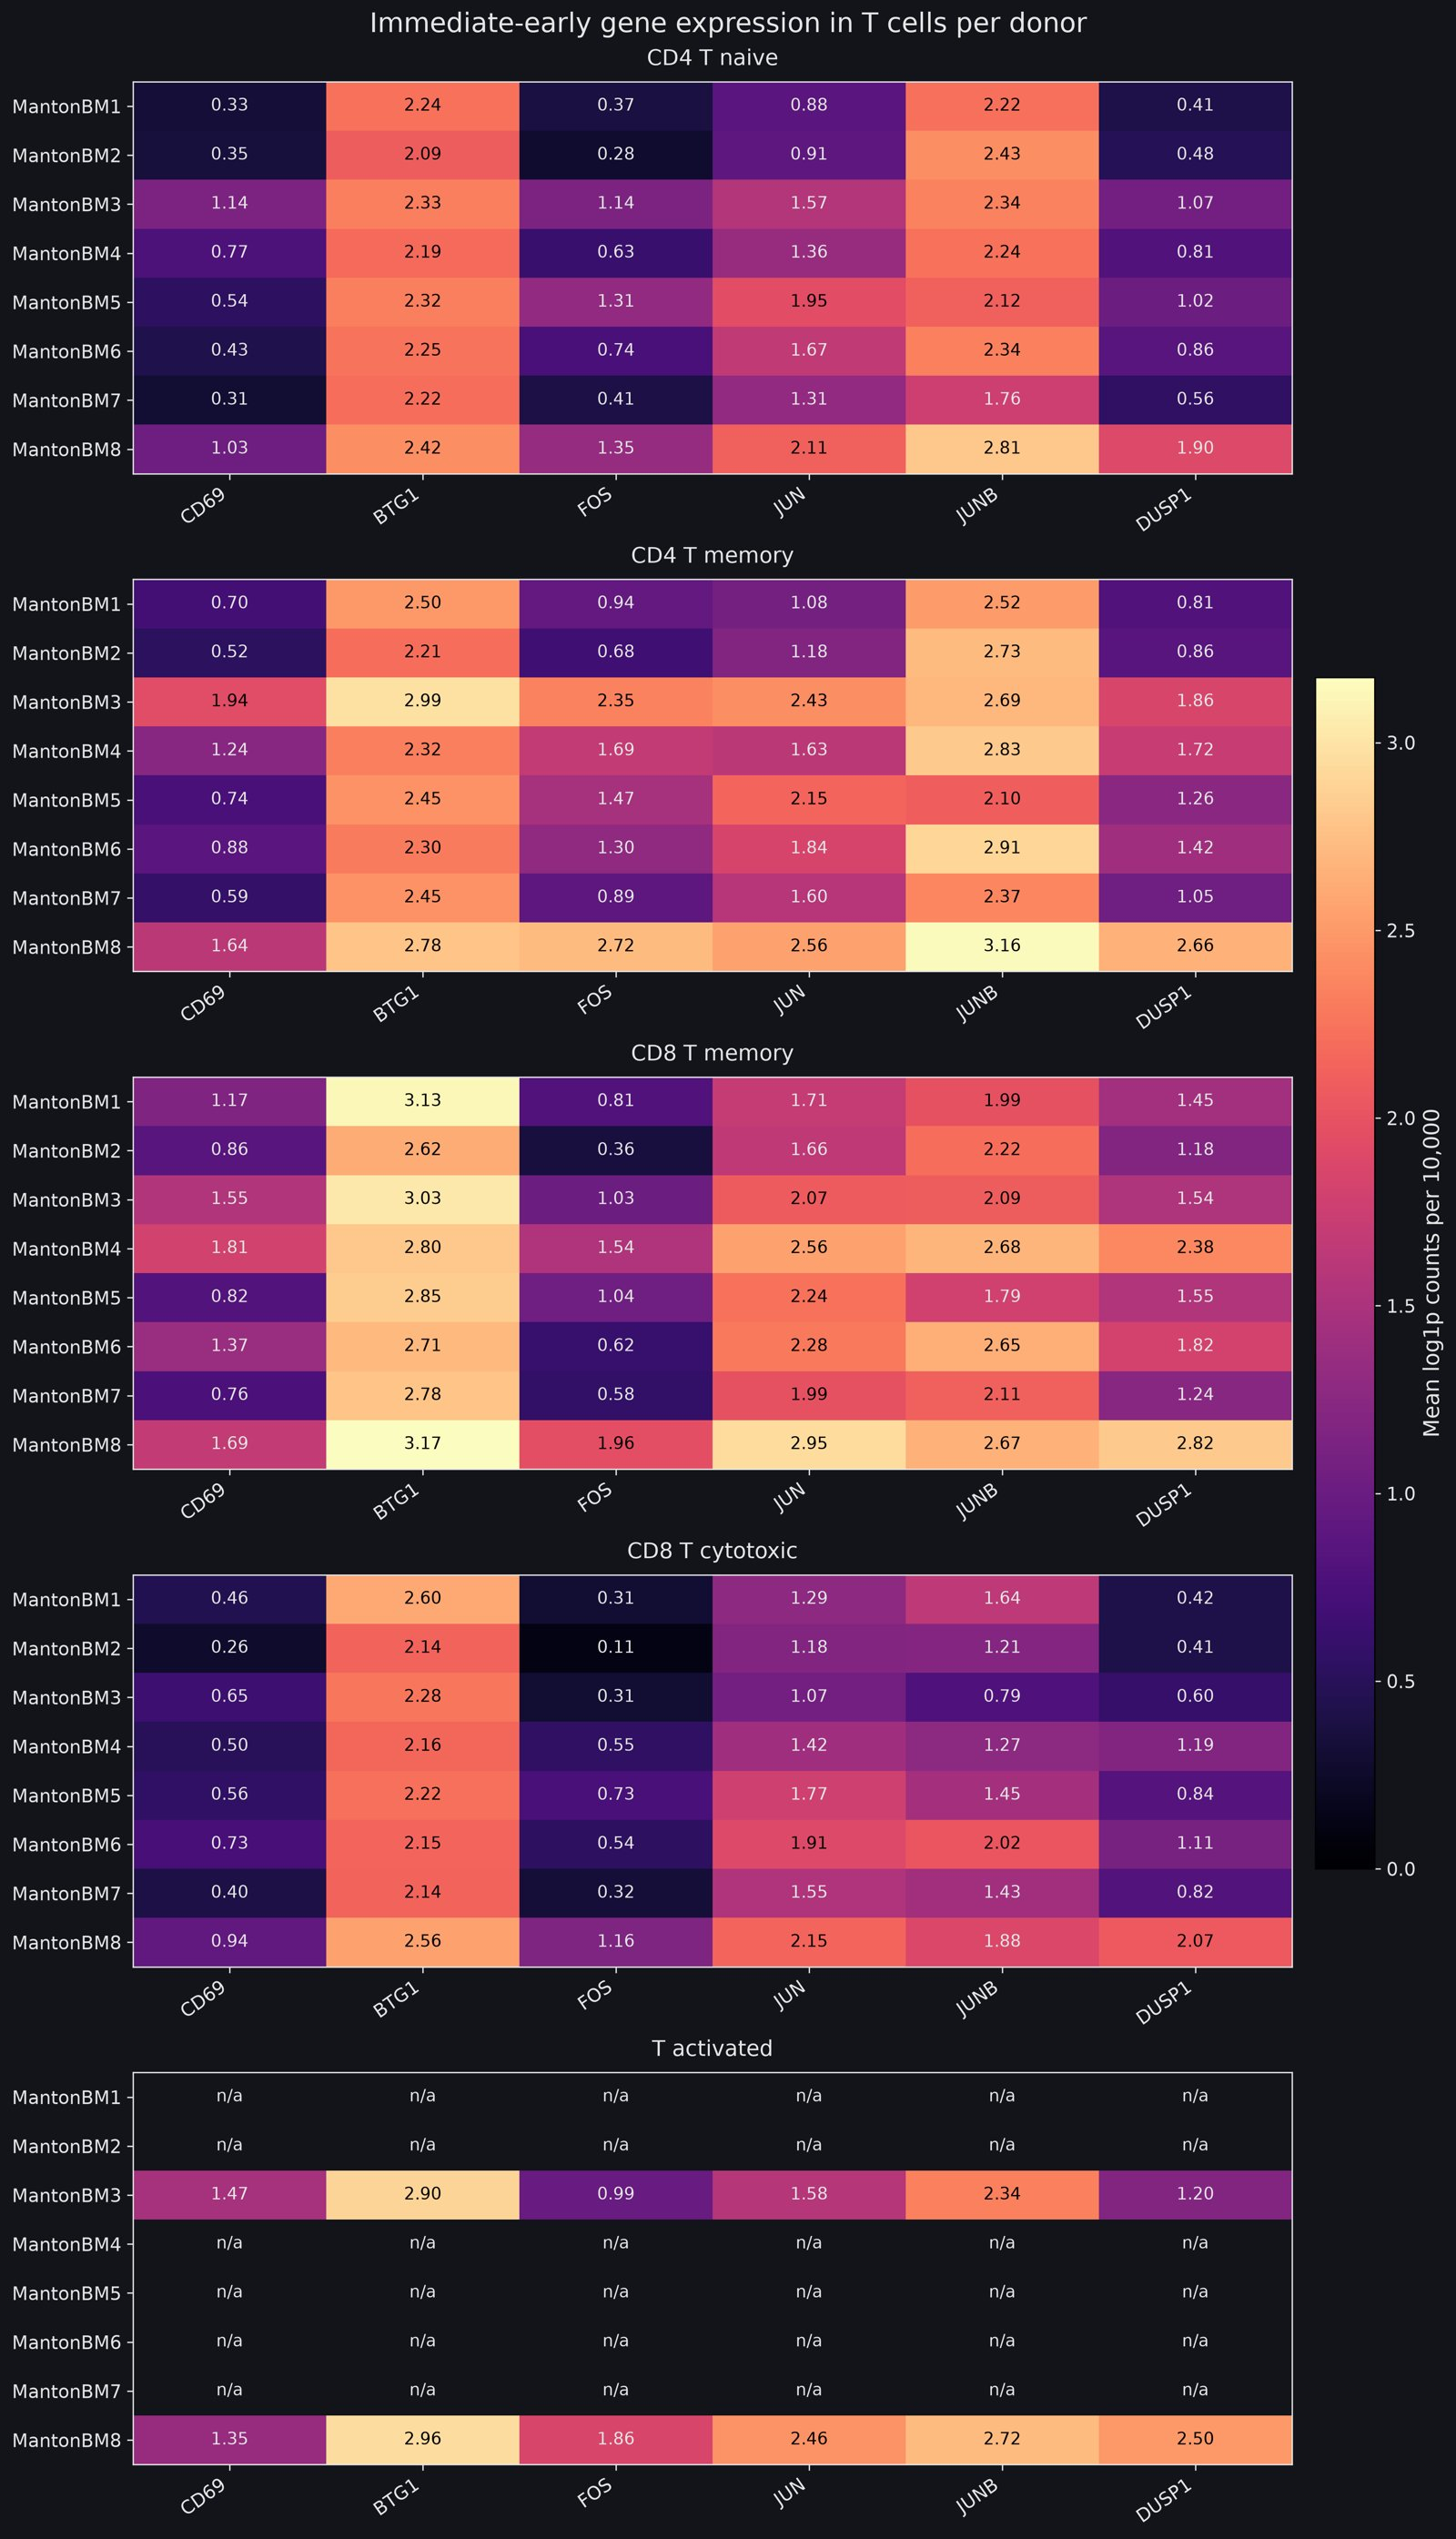

[Full-resolution figure](../figures/deconvolution/donor_diagnostics/donor_diagnostics_activation.png)

In [16]:
show("deconvolution/donor_diagnostics/donor_diagnostics_activation.png", width=600)

- **Mean log-normalised expression per donor**, one panel per T label.
- **The MantonBM8 row is the brightest in FOS, JUN and DUSP1 in every panel**;
  MantonBM1 and MantonBM2 are the darkest rows (weakest programme).
- **BTG1 is high in every donor** (about 2.1-3.2) and separates nothing.

## 5. The PyTorch rewrite: is it the same method?

In [17]:
torch_fit = table("deconvolution/scaden_torch_fit/scaden_torch_fit_summary.csv", index_col=0)
torch_fit.loc[~torch_fit.index.isin(["device"])]

,value
training mixtures,8000
test mixtures,1500
genes,18366
seeds,5
training steps per sub-model,5000
training minutes,18.7
"largest difference from Scaden with Scaden weights, m256",7.238669891385108e-06
"largest difference from Scaden with Scaden weights, m512",1.7894920348870968e-06
"largest difference from Scaden with Scaden weights, m1024",1.2001995086663442e-06
largest deviation of a row sum from 1,2.384185791015625e-07


- **Why:** Scaden runs only on the CPU here and needed the Keras workaround;
  a PyTorch copy on the GPU makes training variants cheap. It is only useful
  if it is the same method, so it was checked two ways.
- **Check 1 - Scaden's own trained weights in the PyTorch network give
  Scaden's predictions** to about a millionth (largest difference 7e-6 to
  1e-6). Network, gene order, scaling and label order are identical.
- **Check 2 - trained from scratch with 5 seeds**, PyTorch differs from Scaden
  (RMSE 0.011-0.014) as much as two PyTorch seeds differ from each other
  (0.0125). Only one Scaden run exists, so Scaden's own seed spread is
  assumed, not measured.
- **About 13 times faster per network** (18.7 min for 15 networks on the GPU,
  against about 16 min per network for Scaden on the CPU).

In [18]:
variants = table("deconvolution/variant_score/variant_score.csv")
scaden_settings = variants[(variants["order"] == "buffer") & (variants["steps"] == 5000)
                           & (variants["cell_type"] != "all")]
seed_medians = scaden_settings.groupby(["level", "subset", "seed"])["ccc"].median()
pd.DataFrame({
    "Scaden": headline.loc["scaden", "ccc_median"],
    "PyTorch, 5 seeds: min": seed_medians.groupby(level=["level", "subset"]).min(),
    "PyTorch, 5 seeds: max": seed_medians.groupby(level=["level", "subset"]).max(),
}).round(2)

Scaden  PyTorch, 5 seeds: min  PyTorch, 5 seeds: max
level subset                                                               
group donor              0.36                   0.32                   0.39
      donor MantonBM1    0.50                   0.42                   0.62
      donor MantonBM8    0.26                   0.23                   0.33
      partial            0.85                   0.82                   0.86
      random             0.72                   0.69                   0.75
label donor              0.40                   0.34                   0.41
      donor MantonBM1    0.37                   0.23                   0.43
      donor MantonBM8    0.22                   0.20                   0.25
      partial            0.79                   0.76                   0.79
      random             0.60                   0.52                   0.62

- **Median per-label CCC: Scaden's value sits inside the PyTorch seed range on
  every subset** (the PyTorch rows here are the 5,000-step, Scaden-shuffle runs
  saved with the training variants; they equal the PyTorch fit to 3e-8).
- **What holds in every seed:** the shrinkage toward 1 in 19, the floor for
  absent labels, the MantonBM8 error (Erythroid late +0.08 to +0.12, CD4 T
  naive −0.11 to −0.13), Myeloid group CCC 0.88-0.93. These are properties of
  the method and the training mixtures, not of one unlucky run.
- **What moves between seeds:** CD4 T memory CCC (−0.14 to 0.27 on the donor
  set), CD4 T naive in MantonBM1 (0.33-0.80), B lineage group (0.63-0.92). The
  CD4 naive/memory boundary is partly decided by chance in training. **A
  difference of 0.1-0.2 in one label between two single runs is not a
  finding.**
- The six PyTorch scoring figures (seed 7) repeat the Scaden shapes; they are
  linked at the end.

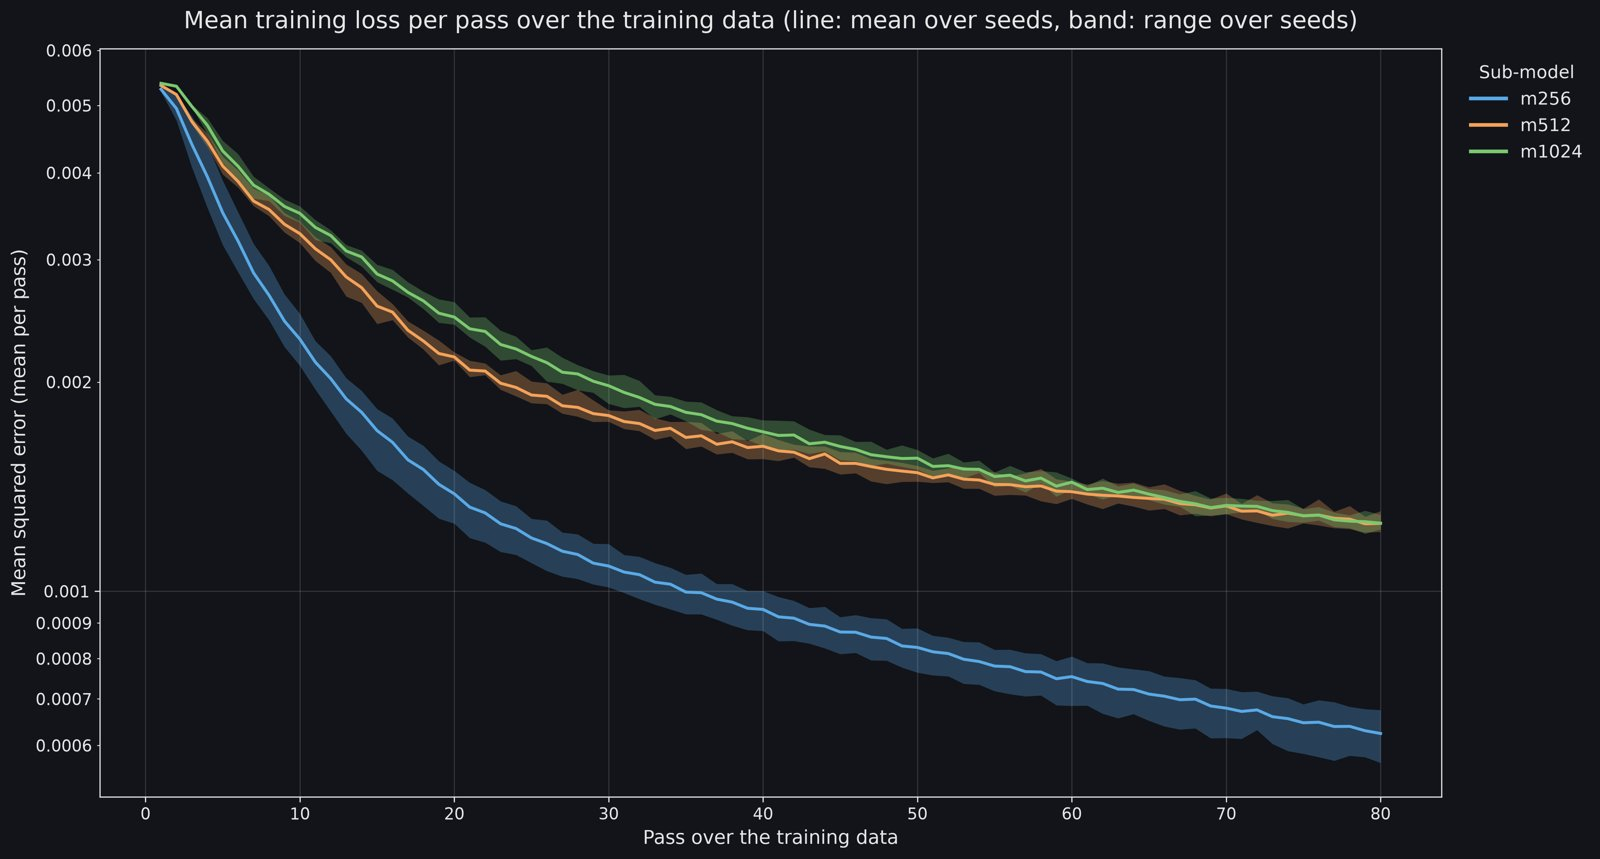

[Full-resolution figure](../figures/deconvolution/scaden_torch_loss/scaden_torch_loss_passes.png)

In [19]:
show("deconvolution/scaden_torch_loss/scaden_torch_loss_passes.png")

- **Training loss per pass over the 8,000 mixtures** (80 passes = 5,000
  steps); line = mean of 5 seeds, band = range.
- **m256 learns fastest and ends at about half the loss** of m512 and m1024
  (0.0006 against 0.0012-0.0013); the two larger networks use dropout, which
  raises training loss without making them worse.
- **The loss is still falling at the last pass for all three** - Scaden's
  default 5,000 steps stop early.

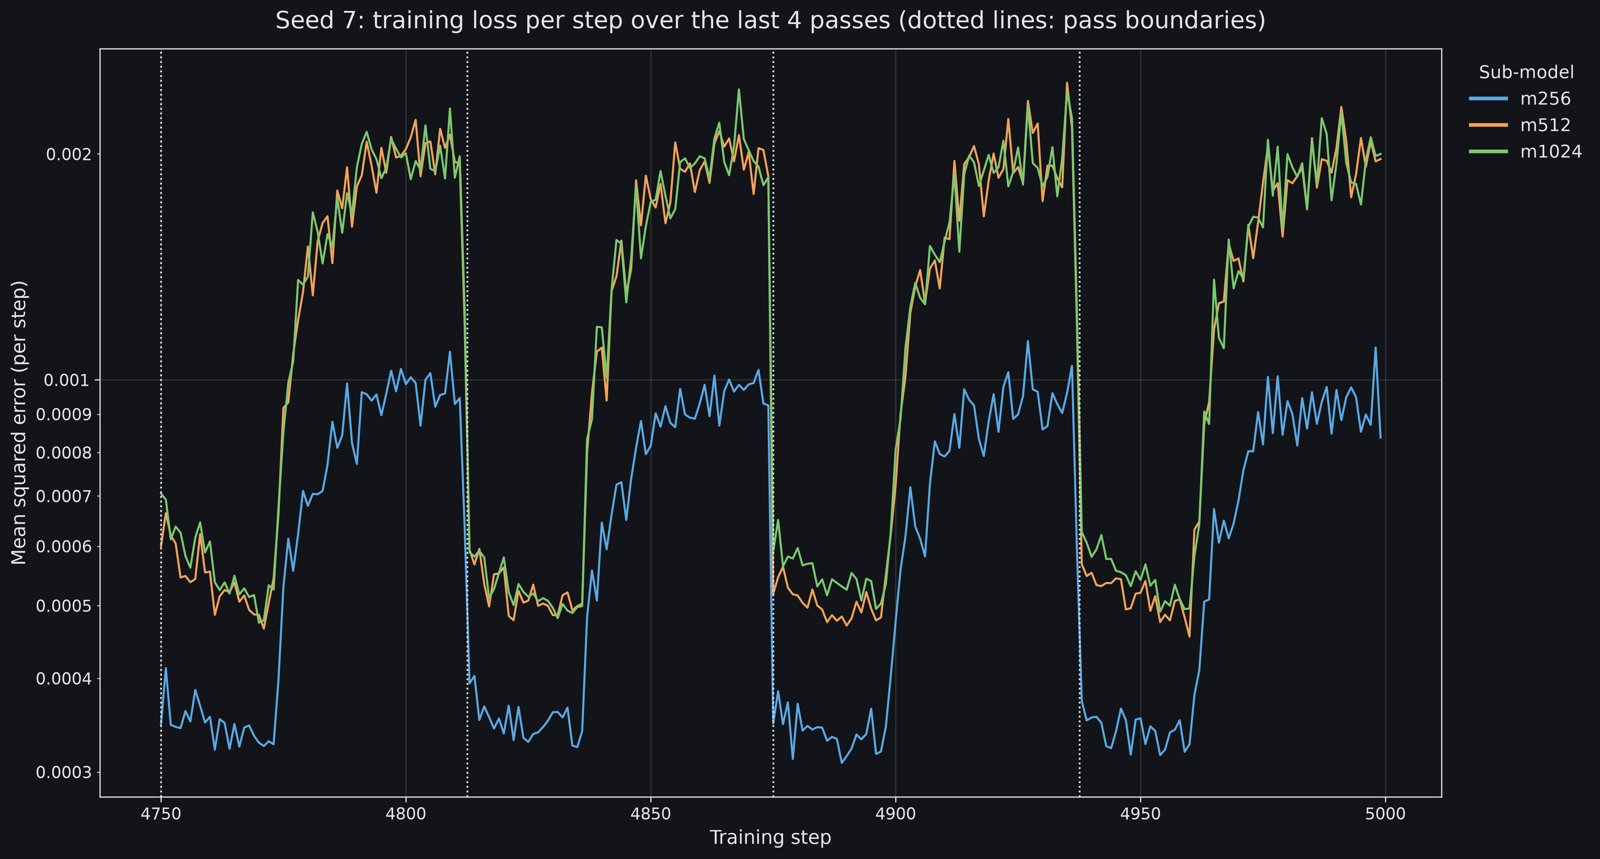

[Full-resolution figure](../figures/deconvolution/scaden_torch_loss/scaden_torch_loss_last_passes.png)

In [20]:
show("deconvolution/scaden_torch_loss/scaden_torch_loss_last_passes.png")

- **Loss per step over the last 4 passes**, seed 7.
- **Every pass splits into a low half and a high half.** The training file
  holds the 4,000 random mixtures first and the 4,000 partial ones second, and
  Scaden shuffles only 1,000 rows at a time - so the model trains about 30
  steps on random mixtures, then about 30 on the harder partial ones. Scaden's
  own simulator writes its file the same way: this is Scaden's behaviour, not
  a fault of the rewrite.

## 6. Training variants: shuffle and length

In [21]:
summary = table("deconvolution/variant_score/variant_score_summary.csv")
summary["median CCC (seed range)"] = (summary["median_ccc_median"].round(2).astype(str) + " ("
                                      + summary["median_ccc_min"].round(2).astype(str) + "–"
                                      + summary["median_ccc_max"].round(2).astype(str) + ")")
summary.pivot(index=["level", "subset"], columns=["order", "steps"], values="median CCC (seed range)")

order                            buffer                                      \
steps                             5000              10000             20000   
level subset                                                                  
group donor            0.35 (0.32–0.39)  0.44 (0.41–0.49)   0.57 (0.52–0.6)   
      donor MantonBM1  0.49 (0.42–0.62)  0.66 (0.56–0.72)  0.75 (0.72–0.78)   
      donor MantonBM8  0.26 (0.23–0.33)   0.4 (0.34–0.45)   0.54 (0.5–0.58)   
      partial          0.85 (0.82–0.86)  0.88 (0.85–0.88)    0.9 (0.9–0.91)   
      random           0.73 (0.69–0.75)   0.78 (0.76–0.8)   0.8 (0.73–0.82)   
label donor             0.4 (0.34–0.41)   0.45 (0.4–0.57)  0.59 (0.54–0.64)   
      donor MantonBM1  0.27 (0.23–0.43)  0.35 (0.29–0.42)  0.51 (0.42–0.57)   
      donor MantonBM8   0.22 (0.2–0.25)  0.33 (0.29–0.35)  0.39 (0.36–0.41)   
      partial          0.77 (0.76–0.79)   0.81 (0.8–0.84)  0.87 (0.82–0.87)   
      random           0.61 (0.52–0.62)  0.66 (0.65–0.67)  0.72 (0.66–0.75)   

order                              full                                      
steps                             5000              10000             20000  
level subset                                                                 
group donor            0.38 (0.28–0.41)  0.52 (0.41–0.55)  0.58 (0.57–0.61)  
      donor MantonBM1   0.53 (0.5–0.61)  0.68 (0.65–0.72)  0.76 (0.69–0.77)  
      donor MantonBM8   0.3 (0.27–0.35)  0.42 (0.37–0.54)  0.57 (0.53–0.63)  
      partial          0.84 (0.82–0.87)  0.87 (0.84–0.89)   0.9 (0.88–0.91)  
      random           0.73 (0.71–0.76)   0.77 (0.76–0.8)  0.81 (0.79–0.81)  
label donor            0.41 (0.34–0.41)  0.49 (0.39–0.53)  0.57 (0.49–0.64)  
      donor MantonBM1   0.33 (0.3–0.48)  0.46 (0.35–0.53)   0.6 (0.55–0.67)  
      donor MantonBM8  0.24 (0.18–0.28)  0.32 (0.27–0.39)  0.37 (0.35–0.47)  
      partial           0.78 (0.74–0.8)  0.81 (0.81–0.83)  0.88 (0.87–0.89)  
      random            0.6 (0.57–0.67)   0.64 (0.6–0.67)  0.73 (0.65–0.74)

- **Design:** 2 shuffles (`buffer` = Scaden's 1,000-row shuffle; `full` = full
  reshuffle every pass) × 5 seeds, trained to 20,000 steps with checkpoints at
  5,000 and 10,000. The `buffer`, 5,000-step column is Scaden's own setting.
- **Training length is the main lever.** Every subset improves from 5,000 to
  10,000 to 20,000 steps, far beyond the seed range: donor labels 0.40 ->
  0.57-0.59, donor groups 0.35 -> 0.57-0.58, MantonBM8 groups 0.26 -> 0.54-0.57.
  **Scaden's default under-trains on this data**, and 20,000 is not yet the
  ceiling.
- **The full shuffle helps a little**, mainly early; at 20,000 steps the two
  are tied on the donor set, except MantonBM1 labels (0.60 against 0.51).
- **Longer training does not make seeds agree more** (donor label range 0.07
  wide at 5,000 steps, 0.11-0.15 at 20,000).
- **Pooled donor RMSE: 0.041 -> 0.031** (labels). The random set stays at 0.025
  throughout.

In [22]:
donor_labels = variants[(variants["level"] == "label") & (variants["subset"] == "donor")
                        & (variants["cell_type"] != "all")]
per_run = donor_labels.groupby(["order", "steps", "cell_type"])[["ccc", "bias"]].median()
start, end = per_run.loc[("buffer", 5000)], per_run.loc[("full", 20000)]
pd.DataFrame({"CCC, Scaden setting": start["ccc"], "CCC, full 20,000": end["ccc"],
              "gain": end["ccc"] - start["ccc"], "bias, Scaden setting": start["bias"],
              "bias, full 20,000": end["bias"]}).sort_values("CCC, full 20,000", ascending=False).round(3)

,"CCC, Scaden setting","CCC, full 20,000",gain,"bias, Scaden setting","bias, full 20,000"
cell_type,,,,,
B naive,0.763,0.872,0.109,-0.025,-0.016
Monocyte classical,0.663,0.849,0.186,-0.031,-0.019
HSPC,0.583,0.832,0.249,0.002,-0.002
Erythroid early,0.697,0.827,0.130,0.004,0.001
Pre-B small,0.409,0.726,0.318,-0.006,-0.005
NK,0.433,0.690,0.257,0.011,0.006
CD4 T naive,0.418,0.657,0.239,-0.098,-0.051
Dendritic cell,0.341,0.648,0.307,0.013,0.003
Pre-B large,0.442,0.641,0.199,0.008,0.003


- **Median over 5 seeds, donor set.** "Scaden setting" = PyTorch with Scaden's
  shuffle and 5,000 steps.
- **14 of 19 labels gain 0.1 or more.** Seven now reach CCC ≥ 0.65 (B naive,
  Monocyte classical, HSPC, Erythroid early, Pre-B small, NK, CD4 T naive),
  against three before.
- **Shrinkage is reduced, not removed**: CD4 T naive bias halves (−0.098 ->
  −0.051), CD8 T memory −0.059 -> −0.040, the Platelet floor +0.018 -> +0.008.
  Every bias keeps its sign.
- **Five labels barely move**: Erythroid late, T activated, T proliferating
  and Platelet stay below 0.15, and CD8 T cytotoxic gains only 0.04. The first
  four are the labels already traced to data problems (too few cells, the
  stress signal, tiny transcriptomes) - more training cannot fix them.
  *Added 15 Oct 2026: the stage report lists only the four.*

In [23]:
bm8 = variants[(variants["subset"] == "donor MantonBM8")
              & variants["cell_type"].isin(["Erythroid late", "T activated", "CD4 T naive", "T cells", "Erythroid"])]
bm8.groupby(["level", "cell_type", "order", "steps"])["bias"].median().unstack(["order", "steps"]).round(3)

order                buffer                 full              
steps                 5000   10000  20000  5000   10000  20000
level cell_type                                               
group Erythroid       0.112  0.096  0.096  0.090  0.084  0.085
      T cells        -0.137 -0.108 -0.095 -0.117 -0.091 -0.095
label CD4 T naive    -0.111 -0.079 -0.083 -0.103 -0.080 -0.079
      Erythroid late  0.108  0.095  0.098  0.090  0.085  0.090
      T activated     0.066  0.058  0.060  0.066  0.063  0.053

- **The MantonBM8 error is not a training problem.** From the Scaden setting
  to full shuffle at 20,000 steps it shrinks by about a quarter (Erythroid
  late +0.108 -> +0.090; T cells group −0.137 -> −0.095) but keeps its size and
  sign. This fits section 4: the error comes from the donor's data.

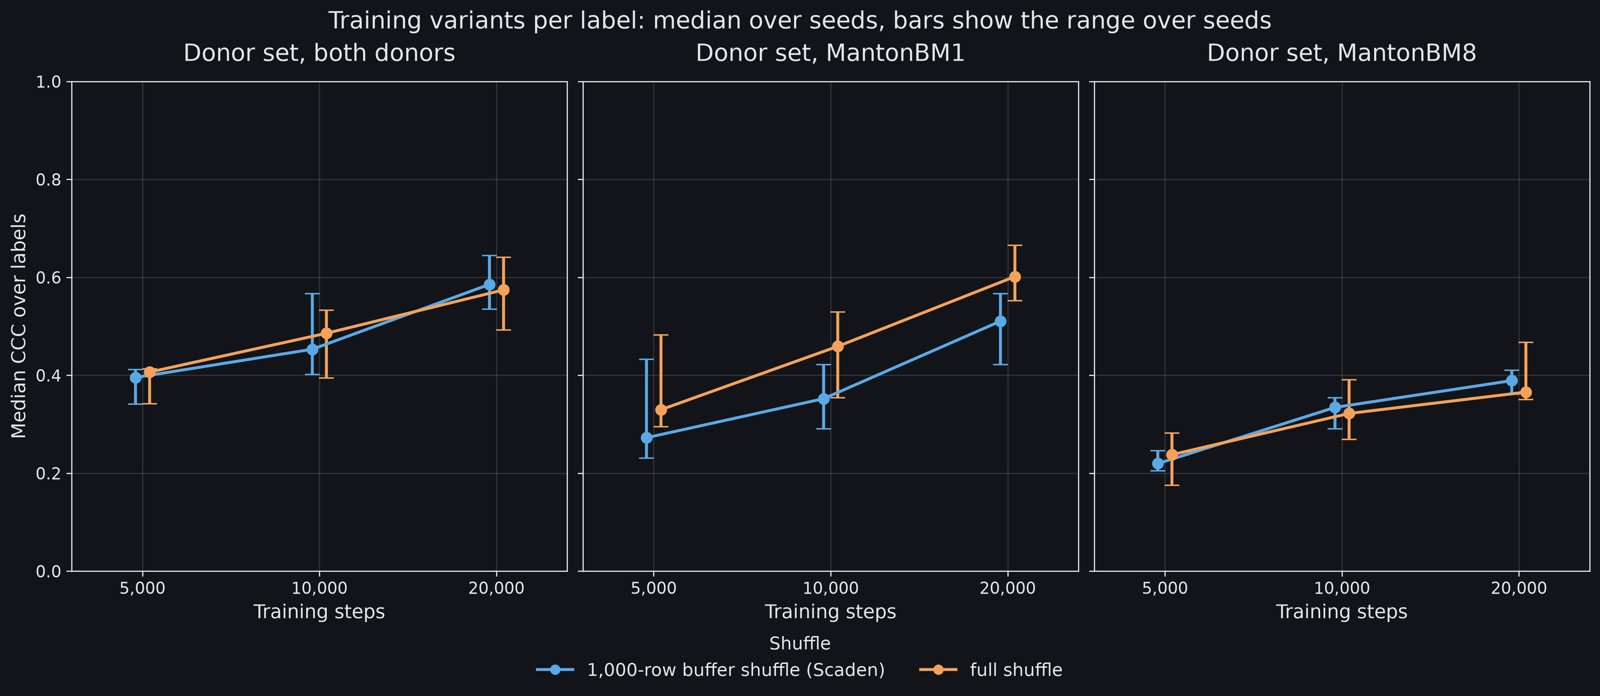

[Full-resolution figure](../figures/deconvolution/variant_score/variant_score_label_trend.png)

In [24]:
show("deconvolution/variant_score/variant_score_label_trend.png")

- **Median per-label CCC against training steps**; blue = Scaden's shuffle,
  orange = full shuffle; bars = seed range.
- **Every line rises.** The two shuffles overlap except MantonBM1, where the
  full shuffle stays above. MantonBM8 (right) stays lowest at every length.

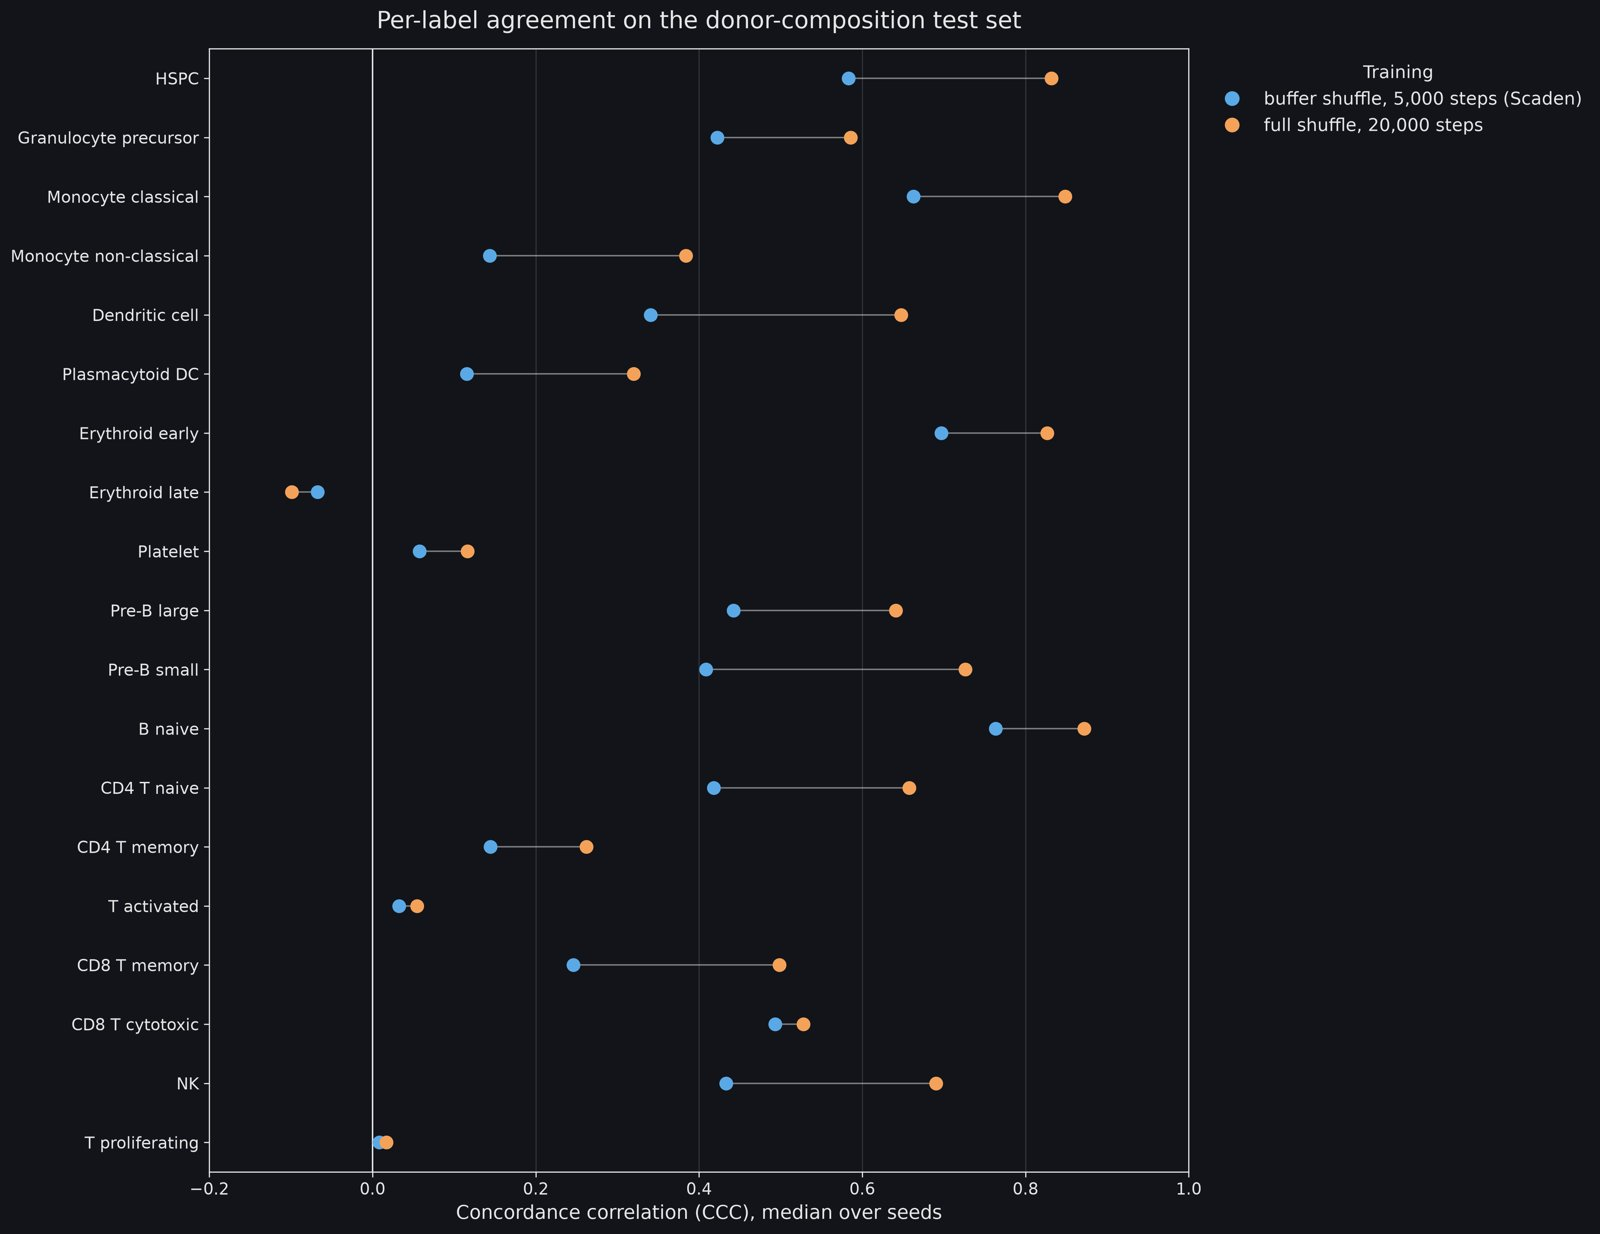

[Full-resolution figure](../figures/deconvolution/variant_score/variant_score_labels.png)

In [25]:
show("deconvolution/variant_score/variant_score_labels.png", width=800)

- **Per-label CCC, donor set**: Scaden setting (blue) against full shuffle at
  20,000 steps (orange).
- **Almost every label moves right**; Erythroid late moves left (−0.07 ->
  −0.10). The flat pairs at the left - T proliferating, T activated, Platelet -
  and the short CD8 T cytotoxic step are the labels training cannot help.

## 7. Real bulk: sorted populations (GSE74246)

In [26]:
display(table("deconvolution/corces_bulk/corces_bulk_summary.csv", index_col=0).T)
truth_bulk = table("deconvolution/corces_bulk/corces_bulk_truth.csv", index_col=0)
display(truth_bulk[truth_bulk["kind"] == "pure"]["sorted_type"].value_counts().rename("pure samples").to_frame().T)
groups = ["HSPC", "Erythroid", "Myeloid", "B lineage", "T cells", "NK"]
truth_bulk[truth_bulk["kind"] != "pure"].groupby("kind")[groups].agg(["mean", "min", "max"]).round(2).T.unstack(level=1)

,genes in the bulk file,genes shared with the single-cell data,shared genes with a RefSeq length,healthy sorted samples,mixtures per set,largest deviation of a true row sum from 1
value,25498.0,15429.0,15123.0,49.0,250.0,3.331e-16


sorted_type,HSC,MPP,CMP,GMP,MEP,Mono,CD4Tcell,CD8Tcell,NKcell,Bcell,LMPP,CLP,Ery
pure samples,4,4,4,4,4,4,4,4,4,4,3,3,3


kind      marrow             random           
            mean   min   max   mean  min   max
HSPC        0.03  0.00  0.08   0.16  0.0  0.50
Erythroid   0.05  0.01  0.11   0.16  0.0  0.39
Myeloid     0.19  0.12  0.29   0.16  0.0  0.48
B lineage   0.17  0.09  0.30   0.17  0.0  0.47
T cells     0.49  0.37  0.63   0.17  0.0  0.56
NK          0.07  0.02  0.16   0.17  0.0  0.43

- **Why this set:** no open healthy marrow bulk RNA-seq with measured cell
  composition was found. GSE74246 has bulk RNA-seq of FACS-sorted healthy
  populations - a sorted sample has a known answer (one cell type), and
  mixtures of sorted profiles at chosen shares give real bulk with known truth.
- **49 healthy samples** from 8 donors (13 types; the 31 leukaemia samples
  dropped). Different from our data: whole-transcript library (long genes get
  more reads), different amplification, older gene annotation.
- **15,429 of 25,498 genes (60.5%) are shared** with the single-cell data.
- **500 mixtures**: 250 `random` (even weights over 6 groups) and 250 `marrow`
  (around the training donors' group composition: T cells about 0.49, Myeloid
  0.19, B lineage 0.17, NK 0.07, Erythroid 0.05, HSPC 0.03).
- **Caveat:** mixing per-million profiles mixes *RNA* shares, not *cell*
  shares; Scaden's labels are cell shares.
- **Dendritic and Platelet have no sorted sample** and cannot be tested.

In [27]:
import numpy as np

correlation = table("deconvolution/corces_bulk/corces_bulk_correlation.csv")
counts_correlation = correlation[correlation["bulk"] == "counts"].set_index("sample")
label_columns = counts_correlation.columns.difference(["bulk", "sorted_type"])
ordered = np.sort(counts_correlation[label_columns].to_numpy(), axis=1)
counts_correlation = counts_correlation.assign(
    best_label=counts_correlation[label_columns].idxmax(axis=1),
    best_r=ordered[:, -1], gap_to_second=ordered[:, -1] - ordered[:, -2])
matches = counts_correlation.groupby(["sorted_type", "best_label"]).size().reset_index(name="samples")
matches["text"] = matches["best_label"] + " " + matches["samples"].astype(str)
counts_correlation.groupby("sorted_type")[["best_r", "gap_to_second"]].median().round(3).join(
    matches.groupby("sorted_type")["text"].agg(", ".join).rename("best-matching label (samples)"))

,best_r,gap_to_second,best-matching label (samples)
sorted_type,,,
Bcell,0.766,0.217,B naive 4
CD4Tcell,0.748,0.007,"CD4 T memory 1, CD4 T naive 3"
CD8Tcell,0.720,0.007,"CD4 T naive 2, CD8 T cytotoxic 1, CD8 T memory 1"
CLP,0.674,0.140,Pre-B large 3
CMP,0.681,0.164,HSPC 4
Ery,0.728,0.069,Erythroid early 3
GMP,0.649,0.032,"Dendritic cell 1, Granulocyte precursor 2, HSPC 1"
HSC,0.604,0.195,HSPC 4
LMPP,0.609,0.097,HSPC 3


- **Model-free check:** each sorted sample correlated with the single-cell
  profile of every label (2,000 most variable genes, log scale).
- **Real bulk is recognisable**: 36 of 49 samples match the expected label;
  best correlations 0.55-0.83. The method gap exists but does not hide
  identity.
- **Clear identities match clearly**: B (gap 0.22), HSC and MPP (0.20), CMP
  (0.16); monocytes have the highest r (0.81).
- **T subtypes cannot be told apart even without a model**: CD4 and CD8 samples
  correlate almost equally with all T labels (gap 0.007). Only the T cells
  group can be tested.
- **CLP matches Pre-B large**, not HSPC - early lymphoid progenitors sit in or
  next to that label in our annotation. **GMP and MEP sit between labels**
  (gap 0.02-0.03): transition states, so a split answer is right.
- **No sorted sample resembles Platelet** (highest r 0.29).
- **Scoring rule that follows:** 38 clearly mapped samples are scored at group
  level; CLP, GMP and MEP (11) are reported as in-between, not scored.

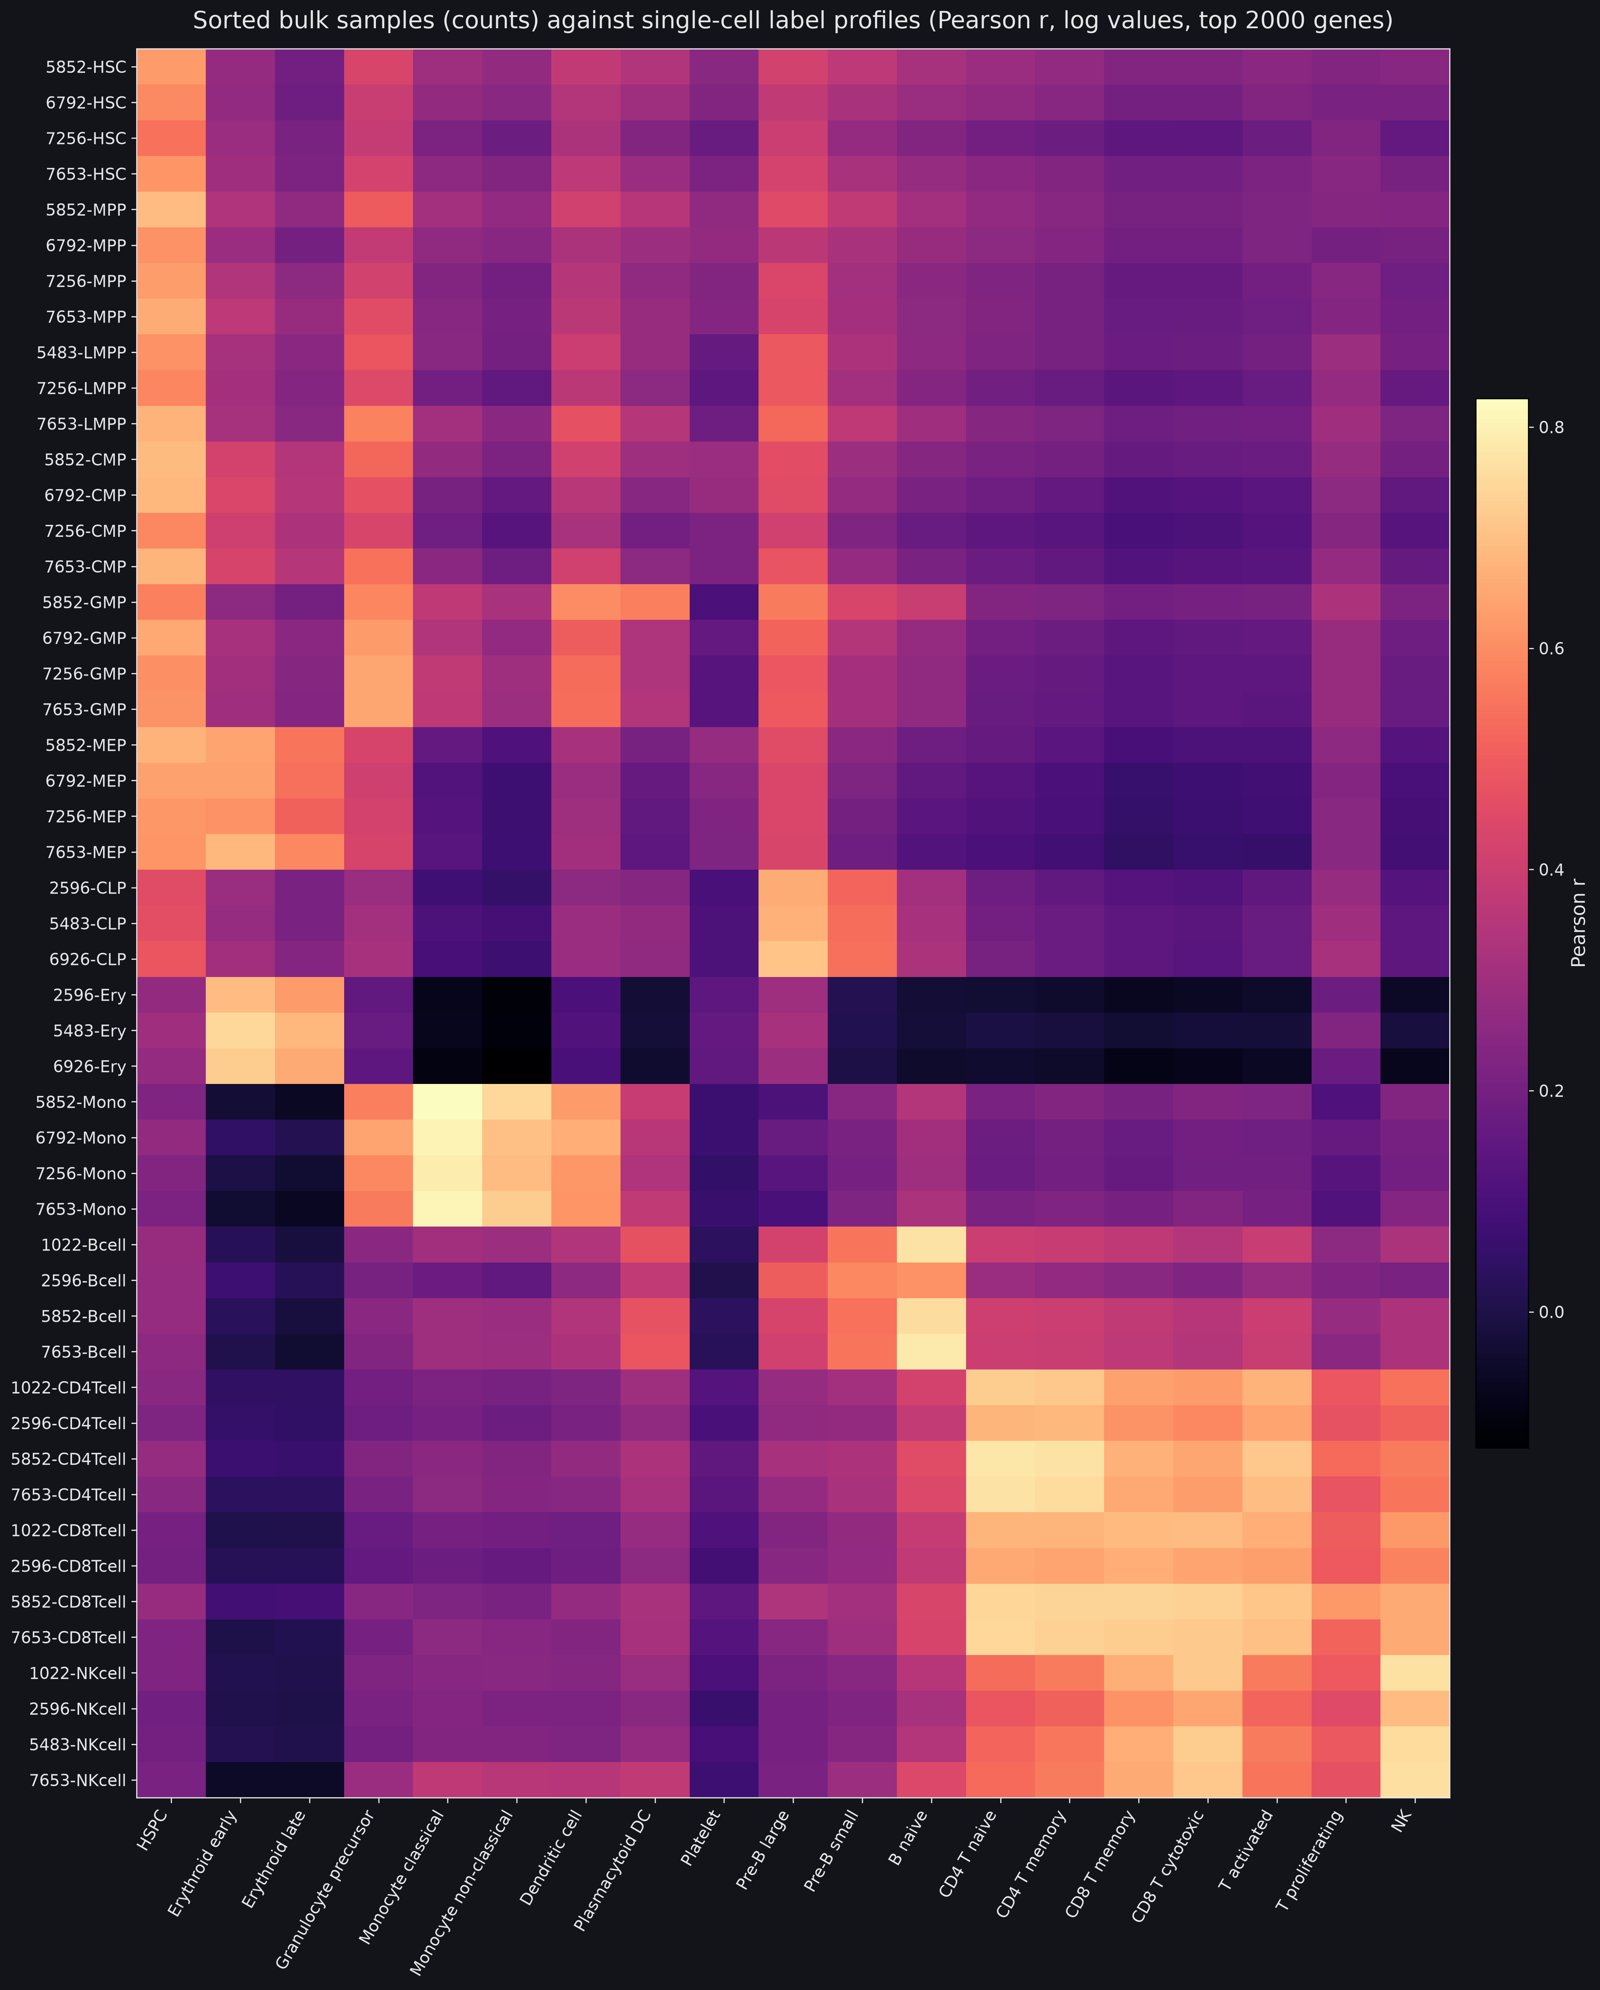

[Full-resolution figure](../figures/deconvolution/corces_bulk/corces_bulk_correlation_counts.png)

In [28]:
show("deconvolution/corces_bulk/corces_bulk_correlation_counts.png", width=650)

- **Sorted samples (rows) against single-cell labels (columns).**
- **Bright diagonal blocks**: HSC-CMP rows on HSPC, Ery on the two erythroid
  labels, Mono on the monocytes, B on B naive, NK on NK.
- **The T block is one bright square**: CD4 and CD8 rows are equally bright
  across all T and NK columns - no subtype separation.
- **CLP rows light Pre-B large**, GMP rows split between Granulocyte precursor,
  Dendritic cell and HSPC, MEP rows between HSPC and the erythroid labels.

In [29]:
pure = table("deconvolution/bulk_score/bulk_score_pure.csv")
counts_pure = pure[pure["bulk"] == "counts"].pivot(index="sorted_type", columns="steps", values="own_group_share")
counts_pure["in between"] = pure[pure["bulk"] == "counts"].groupby("sorted_type")["in_between"].first()
counts_pure.sort_values(20000, ascending=False).round(2)

steps,5000,20000,in between
sorted_type,,,
Mono,0.98,0.98,False
Bcell,0.95,0.96,False
CD4Tcell,0.98,0.96,False
MPP,0.94,0.94,False
HSC,0.93,0.93,False
CD8Tcell,0.91,0.91,False
LMPP,0.81,0.86,False
NKcell,0.82,0.86,False
CMP,0.75,0.80,False


- **Training for real bulk:** the 8,000 training mixtures re-scaled on the
  13,190 genes chosen for the bulk set; full shuffle; 5 seeds; checkpoints at
  5,000 and 20,000 steps. Shares below are means over seeds and samples.
- **A sorted sample of one cell type is recognised almost perfectly**: the 10
  clearly mapped types get 0.77-0.98 of their own group (median 0.92), despite
  a different library method and a third fewer genes.
- **In-between types land where biology puts them** (own-group share is not
  meaningful for them): GMP split HSPC 0.37 / Myeloid 0.35 / Dendritic 0.17,
  MEP Erythroid 0.52 / HSPC 0.35, CLP B lineage 0.63.
- **Longer training helps the hardest types**: Ery 0.62 -> 0.77, CMP 0.75 ->
  0.80, NK 0.82 -> 0.86, LMPP 0.81 -> 0.86.

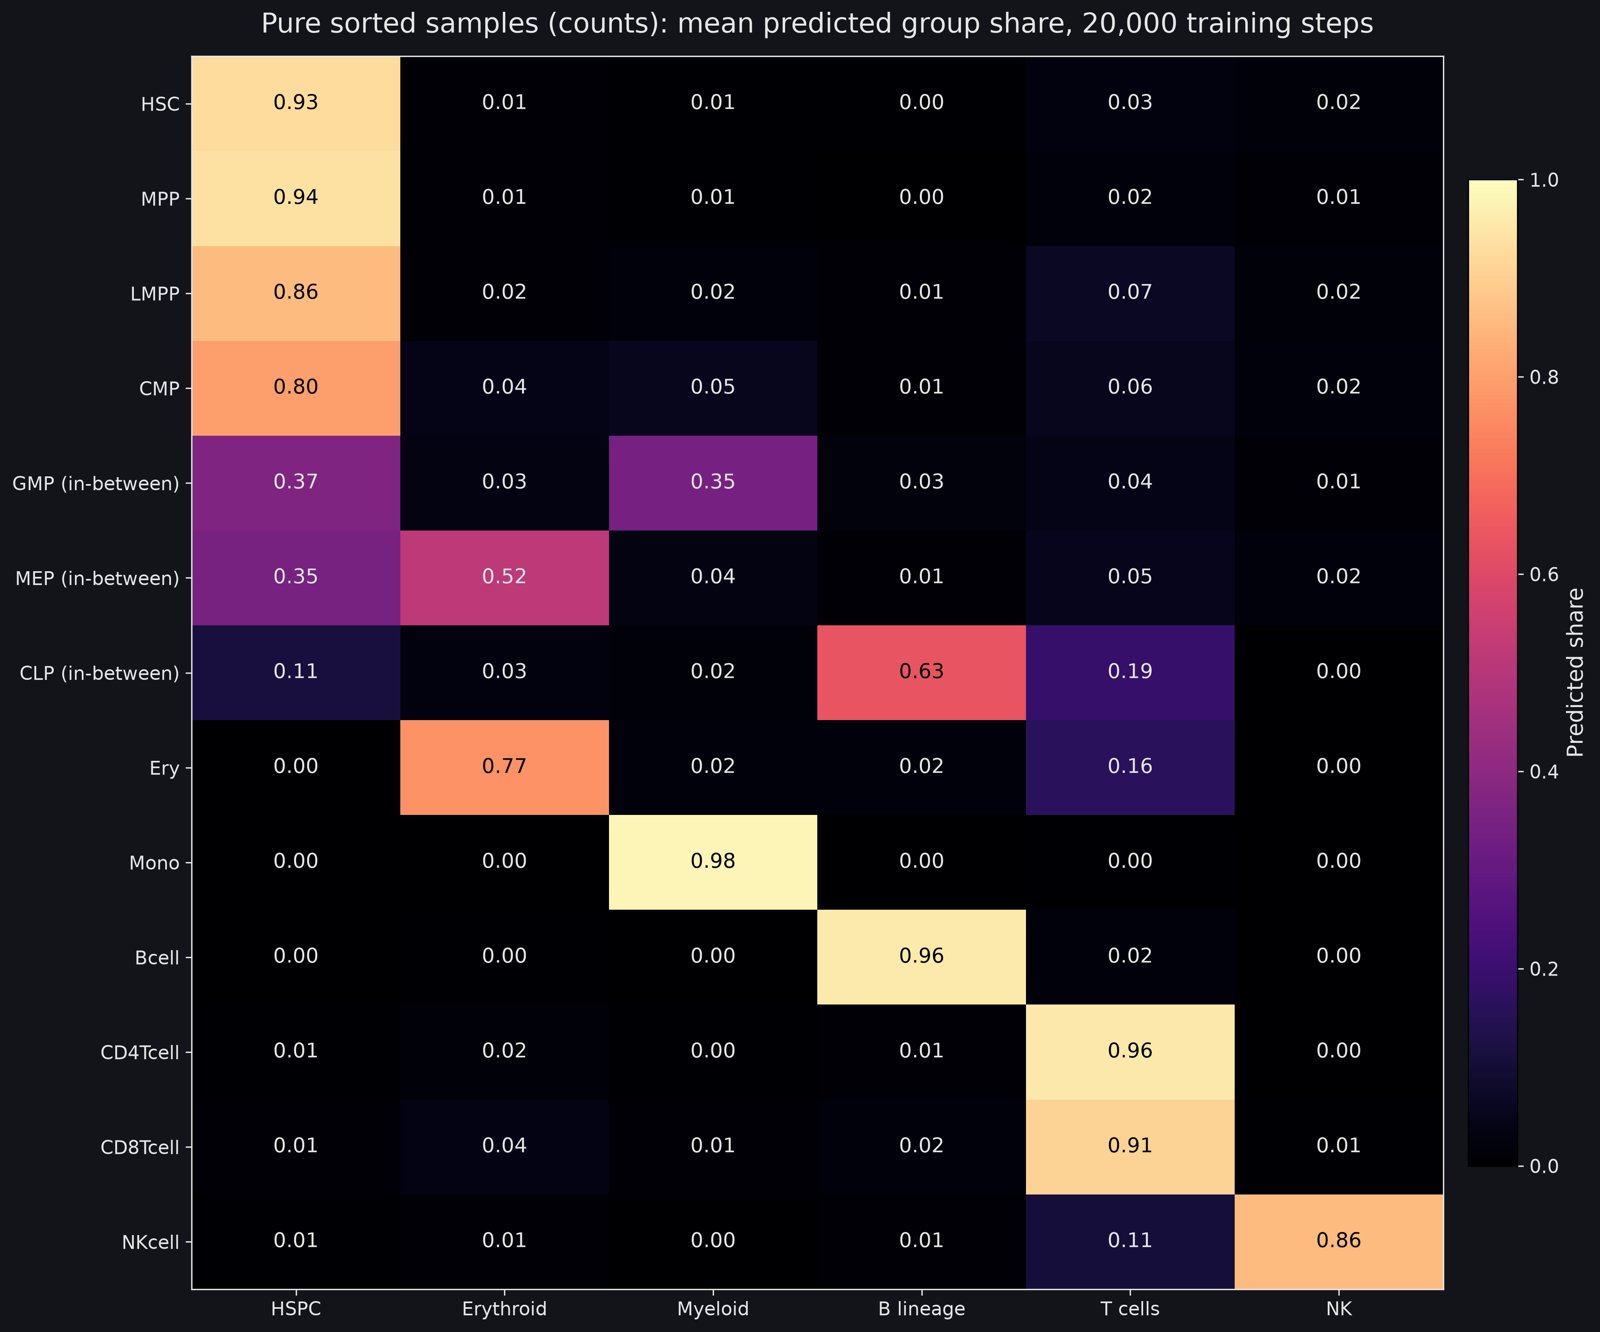

[Full-resolution figure](../figures/deconvolution/bulk_score/bulk_score_pure_counts.png)

In [30]:
show("deconvolution/bulk_score/bulk_score_pure_counts.png", width=750)

- **Predicted group share per sorted type, 20,000 steps.**
- **A clean diagonal.** The off-diagonal leaks run into **T cells**: Ery 0.16,
  NK 0.11, LMPP 0.07, CMP 0.06. NK -> T cells is expected (shared cytotoxic
  programme); Ery -> T cells is not - the T cells group seems to absorb what
  the model cannot place.

In [31]:
bulk_summary = table("deconvolution/bulk_score/bulk_score_summary.csv")
counts_20000 = bulk_summary[(bulk_summary["bulk"] == "counts") & (bulk_summary["steps"] == 20000)]
counts_20000.pivot(index="cell_type", columns="subset",
                   values=["ccc_median", "ccc_min", "ccc_max", "ccc_ensemble", "bias_ensemble"]).round(3)

ccc_median        ccc_min        ccc_max        ccc_ensemble         \
subset        marrow random  marrow random  marrow random       marrow random   
cell_type                                                                       
B lineage      0.159  0.734   0.052  0.406   0.459  0.795        0.591  0.888   
Erythroid      0.050  0.181   0.013  0.071   0.304  0.524        0.092  0.251   
HSPC           0.339  0.709   0.047  0.098   0.679  0.797        0.486  0.682   
Myeloid        0.211  0.776   0.112  0.575   0.644  0.848        0.765  0.878   
NK             0.288  0.749   0.120  0.292   0.446  0.833        0.764  0.861   
T cells        0.196  0.561   0.162  0.473   0.320  0.676        0.416  0.741   
all            0.837  0.698   0.832  0.608   0.922  0.792        0.967  0.840   

          bias_ensemble         
subset           marrow random  
cell_type                       
B lineage        -0.020  0.009  
Erythroid         0.032 -0.070  
HSPC              0.012 -0.045  
Myeloid          -0.005  0.019  
NK               -0.004  0.007  
T cells          -0.049  0.043  
all               0.000  0.000

- **Two ways to score**: per seed (median and range over the 5 seeds) and the
  **ensemble** (mean of the 5 seeds' predictions, 15 networks).
- **Single seeds are unreliable on real bulk.** Each seed shifts whole groups
  up or down in its own direction (Myeloid marrow CCC 0.11-0.64 across seeds).
  Averaging cancels most of it: marrow CCC Myeloid 0.21 -> 0.76, NK 0.29 ->
  0.76, B lineage 0.16 -> 0.59. Real bulk lies outside the training data, where
  each network extrapolates differently. **One Scaden run is not enough for
  real bulk.**
- **Random mixtures work for five of six groups** (ensemble CCC: B lineage
  0.89, Myeloid 0.88, NK 0.86, T cells 0.74, HSPC 0.68).
- **Erythroid fails in mixtures** (0.25 random, 0.09 marrow) although pure Ery
  is recognised (0.77). Cause not tested.
- **Marrow mixtures: right on average, weak sample to sample.** They vary little
  around one composition, so a fixed offset of a few percent dominates
  per-group CCC (0.09-0.76), while the pooled CCC is 0.97.
- **Dendritic is predicted although absent**: 0.02-0.06 per seed at 20,000
  steps; Platelet stays under 0.005.

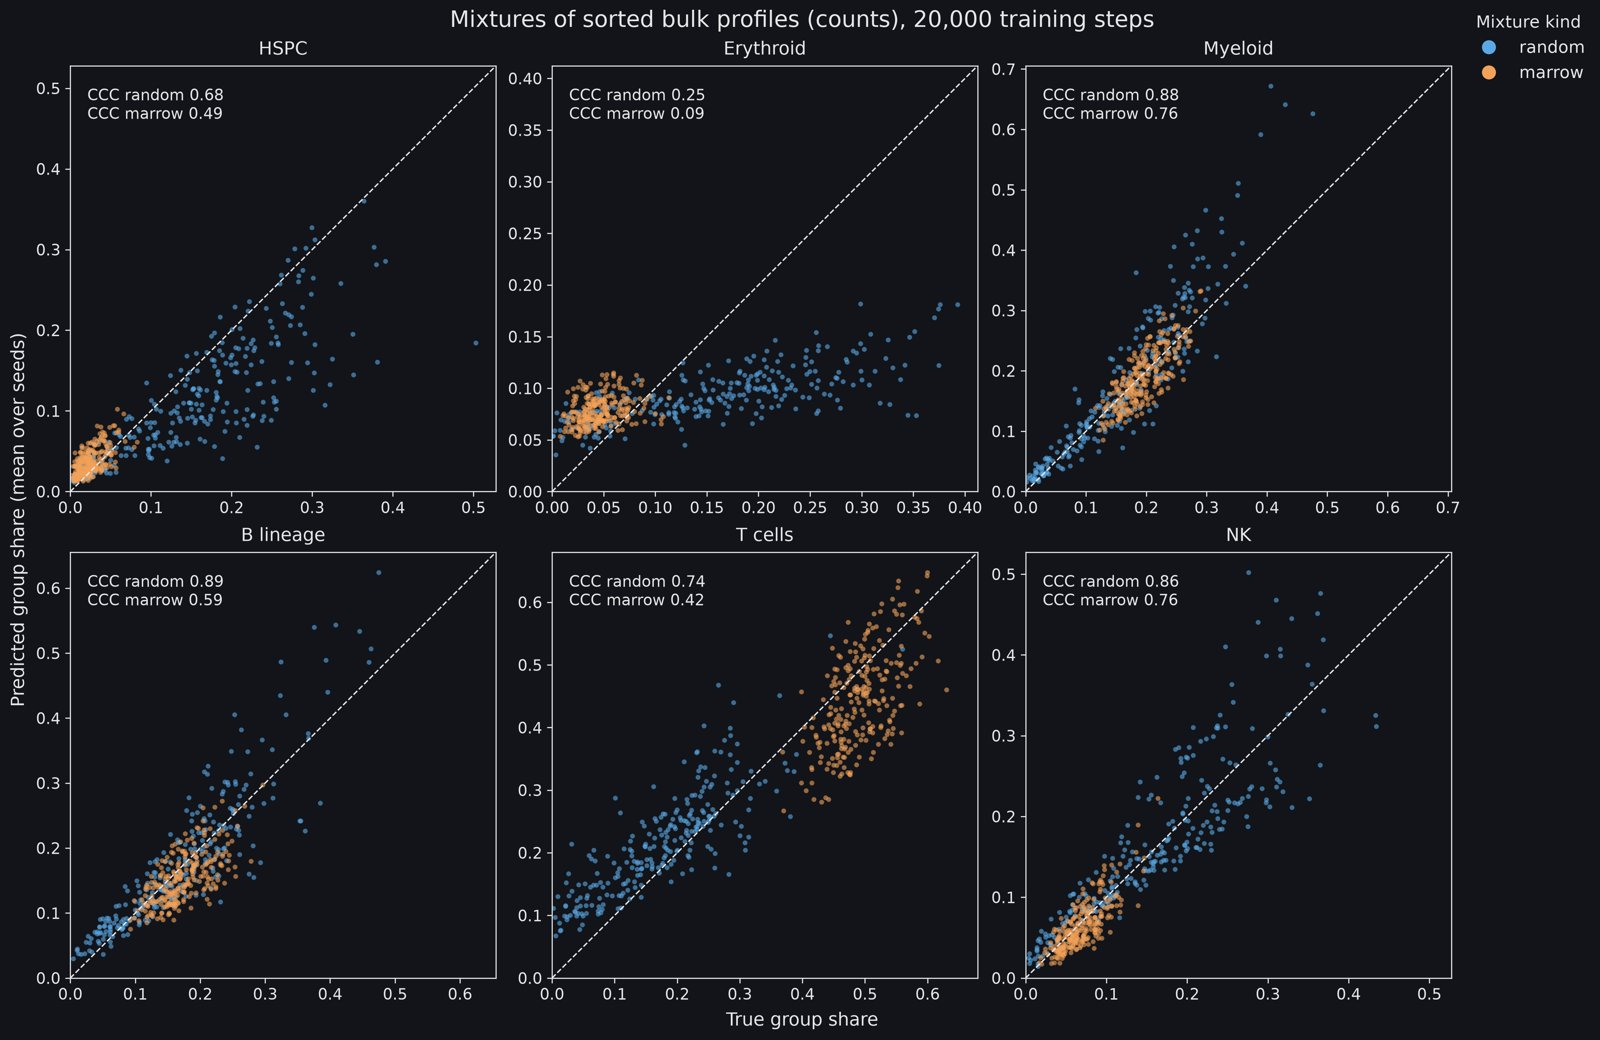

[Full-resolution figure](../figures/deconvolution/bulk_score/bulk_score_mixtures_counts.png)

In [32]:
show("deconvolution/bulk_score/bulk_score_mixtures_counts.png")

- **Ensemble prediction against true group share, 20,000 steps**; blue
  random, orange marrow.
- **Myeloid, B lineage and NK lie along the line.**
- **Erythroid is flat**: predicted 0.05-0.18 whatever the true share (0-0.39).
- **HSPC drifts below the line** above about 0.2; the T cells marrow cloud sits
  just under the line around 0.4-0.6.

In [33]:
ensemble_scores = bulk_summary[bulk_summary["steps"] == 20000].pivot(
    index="cell_type", columns=["subset", "bulk"], values="ccc_ensemble")
display(ensemble_scores.round(2))
lengths = pure[pure["steps"] == 20000].pivot(index="sorted_type", columns="bulk", values="own_group_share")
lengths[~pure.groupby("sorted_type")["in_between"].first()].round(2).T

subset,marrow,random,marrow,random
bulk,counts,counts,length,length
cell_type,,,,
B lineage,0.59,0.89,0.40,0.64
Erythroid,0.09,0.25,0.26,0.21
HSPC,0.49,0.68,0.39,0.25
Myeloid,0.76,0.88,0.40,0.73
NK,0.76,0.86,0.49,0.78
T cells,0.42,0.74,0.26,0.78
all,0.97,0.84,0.93,0.73


sorted_type,Bcell,CD4Tcell,CD8Tcell,CMP,Ery,HSC,LMPP,MPP,Mono,NKcell
bulk,,,,,,,,,,
counts,0.96,0.96,0.91,0.80,0.77,0.93,0.86,0.94,0.98,0.86
length,0.98,0.97,0.95,0.72,0.74,0.93,0.84,0.94,0.99,0.94


- **Gene-length correction** (`length`): whole-transcript counts were divided
  by gene length (hg19 RefSeq) to make them closer to the single-cell
  molecule counts; same samples, same mixture weights, separate training run.
- **Profiles get more similar**: every sorted type correlates 0.03-0.10 higher
  with its single-cell label; pure-sample calls improve for the lymphoid types
  (NK 0.86 -> 0.94, CD8 T 0.91 -> 0.95, B 0.96 -> 0.98).
- **But mixtures get worse**: ensemble CCC falls for 5 of 6 groups on random
  mixtures and 4 of 6 on marrow mixtures; HSPC collapses on random mixtures
  (0.68 -> 0.25). Why HSPC was not tested.
- **The raw counts stay the main result.** Looking more alike is not the same as
  better shares; a correction must be judged on mixtures.

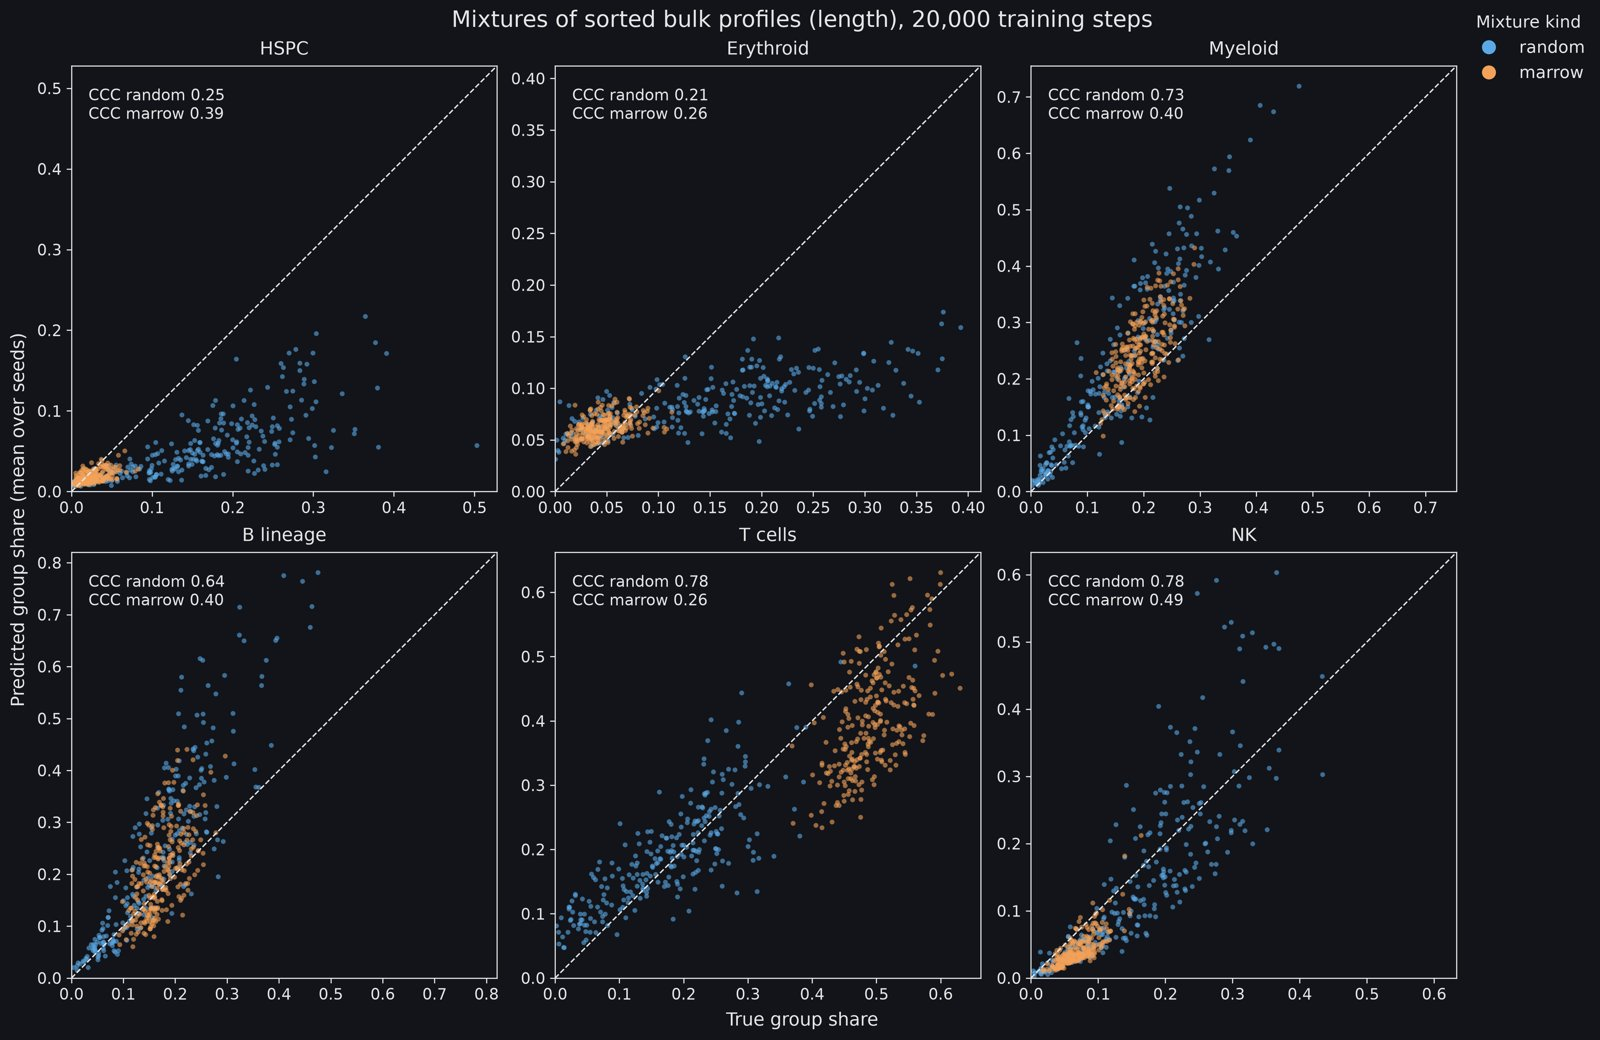

[Full-resolution figure](../figures/deconvolution/bulk_score/bulk_score_mixtures_length.png)

In [34]:
show("deconvolution/bulk_score/bulk_score_mixtures_length.png")

- **Same panels with length-corrected bulk.**
- **HSPC falls far below the line** (predicted up to about 0.2 for true shares
  up to 0.5); **B lineage and Myeloid rise above it** (ensemble bias +0.082 and
  +0.067 on random mixtures). The shares no longer add up the right way.

## 8. Conclusions

**What holds**
- **Scaden ranks samples well but compresses the scale**: donor set median r
  0.77, CCC 0.40; shares are pulled toward 1 in 19 and never fall below about
  0.02.
- **Training longer is the main fix**: 20,000 steps raise the donor-set median
  CCC from 0.40 to about 0.58; seven labels reach 0.65.
- **The PyTorch rewrite is Scaden** - same predictions with the same weights,
  same training behaviour, 13 times faster per network.
- **On real bulk the model works at group level**: sorted samples get 0.77-0.98
  of their own group; real-profile mixtures reach ensemble CCC 0.86-0.89 for
  Myeloid, B lineage and NK.

**What does not, and why**
- **Fine T labels, T activated, T proliferating, Platelet** - too few cells, a
  stress signal, or no separable profile; not usable.
- **MantonBM8**: its T-cell stress (immediate-early) programme is read as
  T activated; its Erythroid late over-prediction is unexplained.
- **Erythroid in real-bulk mixtures** barely moves with its true share.
- **Single training runs disagree**, especially on real bulk; an ensemble of
  seeds is required.
- **Gene-length correction**: more similar profiles, worse shares.

**What can be read from this model**

| output | use |
|---|---|
| Myeloid, B lineage, NK groups | shares and ranking between samples |
| T cells, HSPC groups | ranking; absolute shares with caution |
| Erythroid group | not in mixtures |
| fine T labels, T activated, T proliferating, Platelet | not usable |
| Dendritic | not tested on real bulk; predicted at 0.02-0.06 when absent |
| any share below about 0.02 | not reportable |

**Limits:** no real marrow bulk with measured composition (mixtures check RNA
shares, not cell shares); group level only on real bulk; two held-out donors;
three real cell types missing from the 19 labels (plasma cells, mast cells,
macrophages); realistic training mixtures not tried.

## Figures not shown

All in `figures/deconvolution/`:

- `pseudobulk_train/`: [training mixture shares](../figures/deconvolution/pseudobulk_train/pseudobulk_train_fractions.png)
- `pseudobulk_score/` (Scaden): [group scatter](../figures/deconvolution/pseudobulk_score/pseudobulk_score_scaden_group_scatter.png),
  [group bias](../figures/deconvolution/pseudobulk_score/pseudobulk_score_scaden_group_bias.png)
- `pseudobulk_score/` (PyTorch, seed 7): [label CCC](../figures/deconvolution/pseudobulk_score/pseudobulk_score_scaden_torch_label_ccc.png),
  [label scatter](../figures/deconvolution/pseudobulk_score/pseudobulk_score_scaden_torch_label_scatter.png),
  [label bias](../figures/deconvolution/pseudobulk_score/pseudobulk_score_scaden_torch_label_bias.png),
  [group CCC](../figures/deconvolution/pseudobulk_score/pseudobulk_score_scaden_torch_group_ccc.png),
  [group scatter](../figures/deconvolution/pseudobulk_score/pseudobulk_score_scaden_torch_group_scatter.png),
  [group bias](../figures/deconvolution/pseudobulk_score/pseudobulk_score_scaden_torch_group_bias.png)
- `variant_score/`: [group trend](../figures/deconvolution/variant_score/variant_score_group_trend.png)
- `corces_bulk/`: [correlation, length-corrected](../figures/deconvolution/corces_bulk/corces_bulk_correlation_length.png)
- `bulk_score/`: [pure samples, length-corrected](../figures/deconvolution/bulk_score/bulk_score_pure_length.png)